### Basic neural activity analysis with single camera tracking
#### analyze the firing rate PC1,2,3
#### the following detailed analysis focused on pull related behavioral events
#### the pull action start events are defined based on the movement onset before each pull
#### capture the entire section of neural activity from Pull Start/Onset to pull actions
#### This is the same analysis as basic_neural_analysis_allsessions_basicEvents_PCA_makeBhvNeuronVideos_PullStartToPull_section_continuousBhv; but change to first project all possible continuous variables on PC space, then define based on PC1 (maybe PC2 as well)

In [1]:
# note:
# need to use pyddm environment to run this to be compitable with the hddm pipeline 

In [2]:
import pandas as pd
import numpy as np
from numpy import genfromtxt
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import seaborn
import scipy
import scipy.stats as st
import scipy.io
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import string
import warnings
import pickle
import json

from scipy.ndimage import gaussian_filter1d

import os
import glob
import random
from time import time

from scipy.ndimage import label


### function - get body part location for each pair of cameras

In [3]:
from ana_functions.body_part_locs_eachpair import body_part_locs_eachpair
from ana_functions.body_part_locs_singlecam import body_part_locs_singlecam

### function - align the two cameras

In [4]:
from ana_functions.camera_align import camera_align       

### function - merge the two pairs of cameras

In [5]:
from ana_functions.camera_merge import camera_merge

### function - find social gaze time point

In [6]:
from ana_functions.find_socialgaze_timepoint import find_socialgaze_timepoint
from ana_functions.find_socialgaze_timepoint_singlecam import find_socialgaze_timepoint_singlecam
from ana_functions.find_socialgaze_timepoint_singlecam_wholebody import find_socialgaze_timepoint_singlecam_wholebody
from ana_functions.find_socialgaze_timepoint_singlecam_wholebody_2 import find_socialgaze_timepoint_singlecam_wholebody_2


### function - define time point of behavioral events

In [7]:
from ana_functions.bhv_events_timepoint import bhv_events_timepoint
from ana_functions.bhv_events_timepoint_singlecam import bhv_events_timepoint_singlecam

### function - plot behavioral events

In [8]:
from ana_functions.plot_bhv_events import plot_bhv_events
from ana_functions.plot_bhv_events_levertube import plot_bhv_events_levertube
from ana_functions.plot_continuous_bhv_var_singlecam_PullStartToPull_variedSection import plot_continuous_bhv_var_singlecam_PullStartToPull_variedSection
from ana_functions.plot_continuous_bhv_var_singlecam_PullStartToPull_variedSection_highbhvDimension_to_lowPCspace import plot_continuous_bhv_var_singlecam_PullStartToPull_variedSection_highbhvDimension_to_lowPCspace

from ana_functions.draw_self_loop import draw_self_loop
import matplotlib.patches as mpatches 
from matplotlib.collections import PatchCollection

### function - plot inter-pull interval

In [9]:
from ana_functions.plot_interpull_interval import plot_interpull_interval

### function - make demo videos with skeleton and inportant vectors

In [10]:
from ana_functions.tracking_video_singlecam_demo import tracking_video_singlecam_demo
from ana_functions.tracking_video_singlecam_wholebody_demo import tracking_video_singlecam_wholebody_demo
from ana_functions.tracking_video_singlecam_wholebody_withNeuron_demo import tracking_video_singlecam_wholebody_withNeuron_demo
from ana_functions.tracking_video_singlecam_wholebody_withNeuron_sepbhv_demo import tracking_video_singlecam_wholebody_withNeuron_sepbhv_demo
from ana_functions.tracking_frame_singlecam_wholebody_withNeuron_sepbhv_demo import tracking_frame_singlecam_wholebody_withNeuron_sepbhv_demo

### function - interval between all behavioral events

In [11]:
from ana_functions.bhv_events_interval import bhv_events_interval

### function - spike analysis

In [13]:
from ana_functions.spike_analysis_FR_calculation import spike_analysis_FR_calculation
from ana_functions.plot_spike_triggered_singlecam_bhvevent import plot_spike_triggered_singlecam_bhvevent
from ana_functions.plot_bhv_events_aligned_FR_PullStartToPull_variedSection import plot_bhv_events_aligned_FR_PullStartToPull_variedSection
from ana_functions.plot_strategy_aligned_FR import plot_strategy_aligned_FR

### function - PCA projection

In [14]:
from ana_functions.PCA_around_bhv_events import PCA_around_bhv_events
from ana_functions.PCA_around_bhv_events_video import PCA_around_bhv_events_video
from ana_functions.confidence_ellipse import confidence_ellipse

### function - other useful functions

In [15]:
# for projecting high D bhv variables to small PC space
from ana_functions.singlecam_conBhv_from_highDimension_to_PCspace import get_data_for_singlecam_conBhv_from_highDimension_to_PCspace

In [16]:
# for defining the meaningful social gaze (the continuous gaze distribution that is closest to the pull) 
from ana_functions.keep_closest_cluster_single_trial import keep_closest_cluster_single_trial

In [17]:
# get useful information about pulls
from ana_functions.get_pull_infos import get_pull_infos

In [18]:
# use the gaze vector speed and face mass speed to find the pull action start time within IPI
from ana_functions.find_sharp_increases_withinIPI import find_sharp_increases_withinIPI
from ana_functions.find_sharp_increases_withinIPI import find_sharp_increases_withinIPI_dual_speed

In [19]:
# method 2: find the lowest timepoint then the increase point as the pull onset
from ana_functions.find_rising_onset_after_min_withinIPI import find_rising_onset_after_min_withinIPI
from ana_functions.find_rising_onset_after_min_withinIPI import find_rising_onset_after_min_dual_speed

In [20]:
# method 2: find the lowest timepoint then the increase point as the pull onset
from ana_functions.find_rising_onset_after_min_withinIPI import find_rising_onset_after_min_withinIPI
from ana_functions.find_rising_onset_after_min_withinIPI import find_rising_onset_after_min_dual_speed

## Analyze each session

### prepare the basic behavioral data (especially the time stamps for each bhv events)

In [387]:
# instead of using gaze angle threshold, use the target rectagon to deside gaze info
# ...need to update
sqr_thres_tubelever = 75 # draw the square around tube and lever
sqr_thres_face = 1.15 # a ratio for defining face boundary
sqr_thres_body = 4 # how many times to enlongate the face box boundry to the body


# get the fps of the analyzed video
fps = 30

# get the fs for neural recording
fs_spikes = 20000
fs_lfp = 1000

# frame number of the demo video
# nframes = 0.5*30 # second*30fps
nframes = 45*30 # second*30fps

# re-analyze the video or not
reanalyze_video = 0
redo_anystep = 0

# force manipulation type
# SR_bothchange: self reward, both forces changed
# CO_bothchange: 1s cooperation, both forces changed
# CO_A1change: 1s cooperation, animal 1 forces changed
# CO_A2change: 1s cooperation, animal 2 forces changed

# do OFC sessions or DLPFC sessions
do_OFC = 0
do_DLPFC  = 1
if do_OFC:
    savefile_sufix = '_OFCs'
elif do_DLPFC:
    savefile_sufix = '_DLPFCs'
else:
    savefile_sufix = ''
    
    
# if use onset of the first increase after min
doOnsetAfterMin = 1
if not doOnsetAfterMin:
    doOnsetAfterMin_suffix = 'bhvPCA_'
elif doOnsetAfterMin:
    doOnsetAfterMin_suffix = 'bhvPCA_PullOnsetAfterMin_'

# if use a hmm based method to find the trial start
doHMMmethod = 0
if doHMMmethod:
    doOnsetAfterMin_suffix = 'HMMmethods_'
    

# dannon kanga (combined with dodson kanga; kanga recorded)
if 1:
    if do_DLPFC:
        neural_record_conditions = [
                                    '20240910_Kanga_EffortBasedMC',       '20240911_Kanga_EffortBasedMC',
                                    '20240912_Kanga_EffortBasedSR',       '20240913_Kanga_EffortBasedSR',
                                    '20240916_Kanga_EffortBasedMC',       '20240917_Kanga_EffortBasedSR',
                                    '20240918_Kanga_EffortBasedMC',       '20241008_Kanga_EffortBasedMC',
                                    '20241009_Kanga_DannonEffortBasedMC', '20241010_Kanga_EffortBasedMC',
                                    '20241011_Kanga_DannonEffortBasedMC', '20241014_Kanga_EffortBasedMC',
                                    '20241016_Kanga_DannonEffortBasedMC', '20241017_Kanga_EffortBasedMC',
                                    '20241018_Kanga_DannonEffortBasedMC', '20241022_Kanga_DannonEffortBasedMC',
                                    '20241025_Kanga_DannonEffortBasedMC', '20241101_Kanga_EffortBasedSR',
                                    '20241104_Kanga_EffortBasedSR',
            
                                    '20250505_Kanga_EffortBasedSR_withDodson', '20250506_Kanga_EffortBasedSR_withDodson', 
                                    '20250508_Kanga_EffortBasedSR_withDodson', '20250516_Kanga_EffortBasedSR_withDodson', 
                                    '20250519_Kanga_EffortBasedSR_withDodson', '20250520_Kanga_EffortBasedSR_withDodson', 
                                    '20250522_Kanga_EffortBasedSR_withDodson', '20250523_Kanga_EffortBasedSR_withDodson', 

                                    '20250506_Kanga_DodsonEffortBasedMC',      '20250508_Kanga_DodsonEffortBasedMC',  
                                    '20250512_Kanga_DodsonEffortBasedMC',      '20250520_Kanga_DodsonEffortBasedMC',  
                                    '20250523_Kanga_DodsonEffortBasedMC', 

                                    '20250507_Kanga_KangaEffortBasedMC',       '20250516_Kanga_KangaEffortBasedMC',   
                                    '20250522_Kanga_KangaEffortBasedMC',   
            
                                   ]
        # self and other are corresponding to the recorded animals
        task_conditions = [
                            'self_EffortBasedMC',  'self_EffortBasedMC',
                            'self_EffortBasedSR',  'self_EffortBasedSR',
                            'self_EffortBasedMC',  'self_EffortBasedSR',
                            'self_EffortBasedMC',  'self_EffortBasedMC',
                            'other_EffortBasedMC', 'self_EffortBasedMC',
                            'other_EffortBasedMC', 'self_EffortBasedMC',
                            'other_EffortBasedMC', 'self_EffortBasedMC',
                            'other_EffortBasedMC', 'other_EffortBasedMC',
                            'other_EffortBasedMC', 'self_EffortBasedSR',
                            'self_EffortBasedSR',
            
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            
                            'other_EffortBasedMC', 'other_EffortBasedMC',
                            'other_EffortBasedMC', 'other_EffortBasedMC',
                            'other_EffortBasedMC', 
            
                            'self_EffortBasedMC',  'self_EffortBasedMC',
                            'self_EffortBasedMC',
                          ]
        dates_list = [
                        '20240910', '20240911', '20240912', '20240913',
                        '20240916', '20240917', '20240918', '20241008',
                        '20241009', '20241010', '20241011', '20241014',
                        '20241016', '20241017', '20241018', '20241022',
                        '20241025', '20241101', '20241104',
            
                        # both animals' lever force were changed - Self reward
                        "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                        "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                        # Dodson's lever force were changed
                        "20250506_MC", "20250508",    "20250512_MC", "20250520",
                        "20250523", 
                        # Kanga's lever force were changed
                        "20250507",    "20250516_MC", "20250522"
            
                     ]
        videodates_list = [
                            '20240910', '20240911', '20240912', '20240913',
                            '20240916', '20240917', '20240918', '20241008',
                            '20241009', '20241010', '20241011', '20241014',
                            '20241016', '20241017', '20241018', '20241022',
                            '20241025', '20241101', '20241104',
            
                            # "both animals' lever force were changed - Self reward
                            "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                            "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                            # Dodson's lever force were changed
                            "20250506_MC", "20250508",    "20250512_MC", "20250520",
                            "20250523", 
                            # Kanga's lever force were changed
                            "20250507",    "20250516_MC", "20250522"
                          ] # to deal with the sessions that MC and SR were in the same session
        session_start_times = [ 
                                0.00, 0.00, 90.1, 69.5,
                                62.5, 0.00, 43.5, 59.6,
                                0.00, 66.0, 0.00, 0.00,
                                0.00, 0.00, 0.00, 0.00,
                                0.00, 0.00, 0.00,
            
                                147.1, 0.00, 0.00, 0.00,
                                106.0, 0.00, 0.00, 257.0,    
                                
                                0.00, 151.0, 265.0, 0.00, 
                                66.4,
            
                                0.00, 171.1, 0.00,    
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai0']*19 + ['Dev1/ai9']*16
        
        animal1_fixedorders = ['dannon']*19 + ['dodson']*16
        animal2_fixedorders = ['kanga']*19 + ['kanga']*16

        animal1_filenames = ["Dannon"]*19 + ['Dodson']*16
        animal2_filenames = ["Kanga"]*19 + ['Kanga']*16
        
        recordedanimals = animal2_fixedorders 
        
    elif do_OFC:
        neural_record_conditions = [
                                
                                   ]
        task_conditions = [
                            
                          ]
        dates_list = [
                      
                     ]
        videodates_list = dates_list
        session_start_times = [ 
                                
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai0']*np.shape(dates_list)[0]
    
        animal1_fixedorders = ['dannon']*np.shape(dates_list)[0]
        animal2_fixedorders = ['kanga']*np.shape(dates_list)[0]

        animal1_filenames = ["Dannon"]*np.shape(dates_list)[0]
        animal2_filenames = ["Kanga"]*np.shape(dates_list)[0]
        
        recordedanimals = animal2_fixedorders 
        
        
# dodson kanga (kanga recorded) - do not use becuase the data is not great. consider to conbine with previous section later (all kanga together)
if 0:
    if do_DLPFC:
        neural_record_conditions = [
                        '20250505_Kanga_EffortBasedSR_withDodson', '20250506_Kanga_EffortBasedSR_withDodson', 
                        '20250508_Kanga_EffortBasedSR_withDodson', '20250516_Kanga_EffortBasedSR_withDodson', 
                        '20250519_Kanga_EffortBasedSR_withDodson', '20250520_Kanga_EffortBasedSR_withDodson', 
                        '20250522_Kanga_EffortBasedSR_withDodson', '20250523_Kanga_EffortBasedSR_withDodson', 
            
                        '20250506_Kanga_DodsonEffortBasedMC',      '20250508_Kanga_DodsonEffortBasedMC',  
                        '20250512_Kanga_DodsonEffortBasedMC',      '20250520_Kanga_DodsonEffortBasedMC',  
                        '20250523_Kanga_DodsonEffortBasedMC', 
                        
                        '20250507_Kanga_KangaEffortBasedMC',       '20250516_Kanga_KangaEffortBasedMC',   
                        '20250522_Kanga_KangaEffortBasedMC',   
                                   ]
        # self and other are corresponding to the recorded animals
        task_conditions = [
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            
                            'other_EffortBasedMC', 'other_EffortBasedMC',
                            'other_EffortBasedMC', 'other_EffortBasedMC',
                            'other_EffortBasedMC', 
            
            
                            'self_EffortBasedMC',  'self_EffortBasedMC',
                            'self_EffortBasedMC',  
                          ]
        dates_list = [
                        # both animals' lever force were changed - Self reward
                        "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                        "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                        # Dodson's lever force were changed
                        "20250506_MC", "20250508",    "20250512_MC", "20250520",
                        "20250523", 
                        # Kanga's lever force were changed
                        "20250507",    "20250516_MC", "20250522"
                     ]
        videodates_list = [
                            # "both animals' lever force were changed - Self reward
                            "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                            "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                            # Dodson's lever force were changed
                            "20250506_MC", "20250508",    "20250512_MC", "20250520",
                            "20250523", 
                            # Kanga's lever force were changed
                            "20250507",    "20250516_MC", "20250522"
                          ] # to deal with the sessions that MC and SR were in the same session
        session_start_times = [ 
                                147.1, 0.00, 0.00, 0.00,
                                106.0, 0.00, 0.00, 257.0,    
                                
                                0.00, 151.0, 265.0, 0.00, 
                                66.4,
            
                                0.00, 171.1, 0.00,                     
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai9']*np.shape(dates_list)[0]
        
        animal1_fixedorders = ['dodson']*np.shape(dates_list)[0]
        animal2_fixedorders = ['kanga']*np.shape(dates_list)[0]

        animal1_filenames = ["Dodson"]*np.shape(dates_list)[0]
        animal2_filenames = ["Kanga"]*np.shape(dates_list)[0]
        
        recordedanimals = animal2_fixedorders 
        
    elif do_OFC:
        neural_record_conditions = [
                                
                                   ]
        task_conditions = [
                            
                          ]
        dates_list = [
                      
                     ]
        videodates_list = dates_list
        session_start_times = [ 
                                
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai9']*np.shape(dates_list)[0]
    
        animal1_fixedorders = ['dodson']*np.shape(dates_list)[0]
        animal2_fixedorders = ['kanga']*np.shape(dates_list)[0]

        animal1_filenames = ["Dodson"]*np.shape(dates_list)[0]
        animal2_filenames = ["Kanga"]*np.shape(dates_list)[0]
        
        recordedanimals = animal2_fixedorders 
        
        
# dodson kanga (dodson recorded)
if 0:
    if do_DLPFC:
        neural_record_conditions = [
                        '20250505_Dodson_EffortBasedSR_withKanga', '20250506_Dodson_EffortBasedSR_withKanga', 
                        '20250508_Dodson_EffortBasedSR_withKanga', '20250516_Dodson_EffortBasedSR_withKanga', 
                        '20250519_Dodson_EffortBasedSR_withKanga', '20250520_Dodson_EffortBasedSR_withKanga', 
                        '20250522_Dodson_EffortBasedSR_withKanga', '20250523_Dodson_EffortBasedSR_withKanga', 
            
                        '20250506_Dodson_DodsonEffortBasedMC',      '20250508_Dodson_DodsonEffortBasedMC',  
                        '20250512_Dodson_DodsonEffortBasedMC',      '20250520_Dodson_DodsonEffortBasedMC',  
                        '20250523_Dodson_DodsonEffortBasedMC', 
                        
                        '20250507_Dodson_KangaEffortBasedMC',       '20250516_Dodson_KangaEffortBasedMC',   
                        '20250522_Dodson_KangaEffortBasedMC',   
                                   ]
        # self and other are corresponding to the recorded animals
        task_conditions = [
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            'self_EffortBasedSR', 'self_EffortBasedSR',
                            
                            'self_EffortBasedMC', 'self_EffortBasedMC',
                            'self_EffortBasedMC', 'self_EffortBasedMC',
                            'self_EffortBasedMC', 
            
            
                            'other_EffortBasedMC',  'other_EffortBasedMC',
                            'other_EffortBasedMC',  
                          ]
        dates_list = [
                        # both animals' lever force were changed - Self reward
                        "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                        "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                        # Dodson's lever force were changed
                        "20250506_MC", "20250508",    "20250512_MC", "20250520",
                        "20250523", 
                        # Kanga's lever force were changed
                        "20250507",    "20250516_MC", "20250522"
                     ]
        videodates_list = [
                            # "both animals' lever force were changed - Self reward
                            "20250505",    "20250506_SR", "20250508_SR", "20250516_SR",
                            "20250519",    "20250520_SR", "20250522_SR", "20250523_SR",
                            # Dodson's lever force were changed
                            "20250506_MC", "20250508",    "20250512_MC", "20250520",
                            "20250523", 
                            # Kanga's lever force were changed
                            "20250507",    "20250516_MC", "20250522"
                          ] # to deal with the sessions that MC and SR were in the same session
        session_start_times = [ 
                                147.1, 0.00, 0.00, 0.00,
                                106.0, 0.00, 0.00, 257.0,    
                                
                                0.00, 151.0, 265.0, 0.00, 
                                66.4,
            
                                0.00, 171.1, 0.00,                     
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai0']*np.shape(dates_list)[0]
        
        animal1_fixedorders = ['dodson']*np.shape(dates_list)[0]
        animal2_fixedorders = ['kanga']*np.shape(dates_list)[0]

        animal1_filenames = ["Dodson"]*np.shape(dates_list)[0]
        animal2_filenames = ["Kanga"]*np.shape(dates_list)[0]
        
        recordedanimals = animal1_fixedorders 
        
    elif do_OFC:
        neural_record_conditions = [
                                
                                   ]
        task_conditions = [
                            
                          ]
        dates_list = [
                      
                     ]
        videodates_list = dates_list
        session_start_times = [ 
                                
                              ] # in second
        
        kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
        
        trig_channelnames = ['Dev1/ai0']*np.shape(dates_list)[0]
    
        animal1_fixedorders = ['dodson']*np.shape(dates_list)[0]
        animal2_fixedorders = ['kanga']*np.shape(dates_list)[0]

        animal1_filenames = ["Dodson"]*np.shape(dates_list)[0]
        animal2_filenames = ["Kanga"]*np.shape(dates_list)[0]
        
        recordedanimals = animal1_fixedorders 
    
# a test case
if 0:
    neural_record_conditions = ['20240910_Kanga_EffortBasedMC',]
    dates_list = ['20240910',]
    videodates_list = dates_list
    task_conditions = ['self_EffortBasedMC',]
    session_start_times = [0.00] # in second
    kilosortvers = list((np.ones(np.shape(dates_list))*4).astype(int))
    trig_channelnames = ['Dev1/ai0']*np.shape(dates_list)[0]
    animal1_fixedorders = ['dannon']
    animal2_fixedorders = ['kanga']
    animal1_filenames = ["Dannon"]
    animal2_filenames = ["Kanga"]
    recordedanimals = animal2_fixedorders 

    
    

ndates = np.shape(dates_list)[0]

session_start_frames = session_start_times * fps # fps is 30Hz

# video tracking results info
animalnames_videotrack = ['dodson','scorch'] # does not really mean dodson and scorch, instead, indicate animal1 and animal2
bodypartnames_videotrack = ['rightTuft','whiteBlaze','leftTuft','rightEye','leftEye','mouth']


# which camera to analyzed
cameraID = 'camera-2'
cameraID_short = 'cam2'


# location of levers and tubes for camera 2
# get this information using DLC animal tracking GUI, the results are stored: 
# /home/ws523/marmoset_tracking_DLCv2/marmoset_tracking_with_lever_tube-weikang-2023-04-13/labeled-data/
considerlevertube = 1
considertubeonly = 0
# # camera 1
# lever_locs_camI = {'dodson':np.array([645,600]),'scorch':np.array([425,435])}
# tube_locs_camI  = {'dodson':np.array([1350,630]),'scorch':np.array([555,345])}
# # camera 2
lever_locs_camI = {'dodson':np.array([1335,715]),'scorch':np.array([550,715])}
tube_locs_camI  = {'dodson':np.array([1550,515]),'scorch':np.array([350,515])}
# # lever_locs_camI = {'dodson':np.array([1335,715]),'scorch':np.array([550,715])}
# # tube_locs_camI  = {'dodson':np.array([1650,490]),'scorch':np.array([250,490])}
# # camera 3
# lever_locs_camI = {'dodson':np.array([1580,440]),'scorch':np.array([1296,540])}
# tube_locs_camI  = {'dodson':np.array([1470,375]),'scorch':np.array([805,475])}


if np.shape(session_start_times)[0] != np.shape(dates_list)[0]:
    exit()

    
# define bhv events summarizing variables     
pull_rts_all_dates = dict.fromkeys(dates_list, [])

pull_infos_all_dates = dict.fromkeys(dates_list, []) # keep some useful information about pulls - time from last reward, number of preceding failed pull, force conditions

bhvtoPC1_loadings_all_dates = dict.fromkeys(dates_list, [])
bhvPC123explained_all_dates = dict.fromkeys(dates_list, [])

bhvevents_pullstartTopull_aligned_FR_allevents_all_dates = dict.fromkeys(dates_list, [])

pullstartTopull_trig_events_all_dates = dict.fromkeys(dates_list, [])

# where to save the summarizing data
data_saved_folder = '/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/3d_recontruction_analysis_forceManipulation_task_data_saved/'

# neural data folder
neural_data_folder = '/gpfs/radev/pi/nandy/jadi_gibbs_data/Marmoset_neural_recording/'


    

In [388]:
print(np.shape(neural_record_conditions))
print(np.shape(task_conditions))
print(np.shape(dates_list))
print(np.shape(videodates_list)) 
print(np.shape(session_start_times))

print(np.shape(kilosortvers))

print(np.shape(trig_channelnames))
print(np.shape(animal1_fixedorders)) 
print(np.shape(recordedanimals))
print(np.shape(animal2_fixedorders))

print(np.shape(animal1_filenames))
print(np.shape(animal2_filenames))  

(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)


In [389]:
# save those basic session wised information so that it's easier to do summazing analysis
if 0:
    data_saved_subfolder = data_saved_folder+'data_saved_singlecam_wholebody'+savefile_sufix+'/'+cameraID+'/'+\
        animal1_fixedorders[0]+animal2_fixedorders[0]+'_'+recordedanimals[0]+'Recorded'+'/'
    
    with open(data_saved_subfolder+'/neural_record_conditions_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(neural_record_conditions, f)  
            
    with open(data_saved_subfolder+'/task_conditions_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(task_conditions, f)  
    
    with open(data_saved_subfolder+'/dates_list_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(dates_list, f) 
            
    with open(data_saved_subfolder+'/animal1_fixedorders_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(animal1_fixedorders, f) 
    with open(data_saved_subfolder+'/animal2_fixedorders_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(animal2_fixedorders, f) 
            
    with open(data_saved_subfolder+'/recordedanimals_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'.pkl', 'wb') as f:
            pickle.dump(recordedanimals, f) 
            
    

In [390]:
# basic behavior analysis (define time stamps for each bhv events, etc)

try:
    if redo_anystep:
        dummy
    
    # dummpy
    
    #
    print('loading all data')
    
    # load saved data
    data_saved_subfolder = data_saved_folder+'data_saved_singlecam_wholebody'+savefile_sufix+'/'+cameraID+'/'+\
        animal1_fixedorders[0]+animal2_fixedorders[0]+'_'+recordedanimals[0]+'Recorded'+'/'
    
    
    with open(data_saved_subfolder+'/bhvtoPC1_loadings_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        bhvtoPC1_loadings_all_dates  = pickle.load(f)
        
    with open(data_saved_subfolder+'/bhvPC123explained_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        bhvPC123explained_all_dates  = pickle.load(f)
        
    with open(data_saved_subfolder+'/pull_rts_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        pull_rts_all_dates  = pickle.load(f)
    
    with open(data_saved_subfolder+'/pull_infos_all_dates_'+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        pull_infos_all_dates  = pickle.load(f)  
    
    with open(data_saved_subfolder+'/bhvevents_pullstartTopull_aligned_FR_allevents_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        bhvevents_pullstartTopull_aligned_FR_allevents_all_dates = pickle.load(f) 
        
    with open(data_saved_subfolder+'/pullstartTopull_trig_events_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'rb') as f:
        pullstartTopull_trig_events_all_dates = pickle.load(f) 
        
    print('all data from all dates are loaded; pull start focus')

except:

    print('analyze all dates')

    for idate in np.arange(0,ndates,1):
        
        date_tgt = dates_list[idate]
        videodate_tgt = videodates_list[idate]
        
        neural_record_condition = neural_record_conditions[idate]
        
        session_start_time = session_start_times[idate]
        
        kilosortver = kilosortvers[idate]

        trig_channelname = trig_channelnames[idate]
        
        animal1_filename = animal1_filenames[idate]
        animal2_filename = animal2_filenames[idate]
        
        animal1_fixedorder = [animal1_fixedorders[idate]]
        animal2_fixedorder = [animal2_fixedorders[idate]]
        
        recordedanimal = recordedanimals[idate]
        
        #
        pull_rts_all_dates[date_tgt] = dict.fromkeys([animal1_fixedorder[0],animal2_fixedorder[0]],[])
        
        #
        bhvtoPC1_loadings_all_dates[date_tgt] = dict.fromkeys([animal1_fixedorder[0],animal2_fixedorder[0]],[])
        bhvPC123explained_all_dates[date_tgt] = dict.fromkeys([animal1_fixedorder[0],animal2_fixedorder[0]],[])
        
        # load behavioral results
        try:
            bhv_data_path = "/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/marmoset_tracking_bhv_data_forceManipulation_task/"+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"/"
            trial_record_json = glob.glob(bhv_data_path +date_tgt+"_"+animal2_filename+"_"+animal1_filename+"_TrialRecord_" + "*.json")
            bhv_data_json = glob.glob(bhv_data_path + date_tgt+"_"+animal2_filename+"_"+animal1_filename+"_bhv_data_" + "*.json")
            session_info_json = glob.glob(bhv_data_path + date_tgt+"_"+animal2_filename+"_"+animal1_filename+"_session_info_" + "*.json")
            lever_reading_json = glob.glob(bhv_data_path + date_tgt+"_"+animal2_filename+"_"+animal1_filename+"_lever_reading_" + "*.json") 
            #
            trial_record = pd.read_json(trial_record_json[0])
            bhv_data = pd.read_json(bhv_data_json[0])
            session_info = pd.read_json(session_info_json[0])
            lever_reading = pd.read_json(lever_reading_json[0])
        except:
            bhv_data_path = "/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/marmoset_tracking_bhv_data_forceManipulation_task/"+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"/"
            trial_record_json = glob.glob(bhv_data_path + date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_TrialRecord_" + "*.json")
            bhv_data_json = glob.glob(bhv_data_path + date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_bhv_data_" + "*.json")
            session_info_json = glob.glob(bhv_data_path + date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_session_info_" + "*.json")
            lever_reading_json = glob.glob(bhv_data_path + date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_lever_reading_" + "*.json")             
            #
            trial_record = pd.read_json(trial_record_json[0])
            bhv_data = pd.read_json(bhv_data_json[0])
            session_info = pd.read_json(session_info_json[0])
            lever_reading = pd.read_json(lever_reading_json[0])

        # get animal info from the session information
        animal1 = session_info['lever1_animal'][0].lower()
        animal2 = session_info['lever2_animal'][0].lower()
        
        # successful trial or not
        succtrial_ornot = np.array((trial_record['rewarded']>0).astype(int))
        succpull1_ornot = np.array((np.isin(bhv_data[bhv_data['behavior_events']==1]['trial_number'],trial_record[trial_record['rewarded']>0]['trial_number'])).astype(int))
        succpull2_ornot = np.array((np.isin(bhv_data[bhv_data['behavior_events']==2]['trial_number'],trial_record[trial_record['rewarded']>0]['trial_number'])).astype(int))
        succpulls_ornot = [succpull1_ornot,succpull2_ornot]

        # clean up the trial_record
        warnings.filterwarnings('ignore')
        trial_record_clean = pd.DataFrame(columns=trial_record.columns)
        for itrial in np.arange(0,np.max(trial_record['trial_number']),1):
            # trial_record_clean.loc[itrial] = trial_record[trial_record['trial_number']==itrial+1].iloc[[0]]
            trial_record_clean = trial_record_clean.append(trial_record[trial_record['trial_number']==itrial+1].iloc[[0]])
        trial_record_clean = trial_record_clean.reset_index(drop = True)

        # change bhv_data time to the absolute time
        time_points_new = pd.DataFrame(np.zeros(np.shape(bhv_data)[0]),columns=["time_points_new"])
        for itrial in np.arange(0,np.max(trial_record_clean['trial_number']),1):
            ind = bhv_data["trial_number"]==itrial+1
            new_time_itrial = bhv_data[ind]["time_points"] + trial_record_clean["trial_starttime"].iloc[itrial]
            time_points_new["time_points_new"][ind] = new_time_itrial
        bhv_data["time_points"] = time_points_new["time_points_new"]
        bhv_data = bhv_data[bhv_data["time_points"] != 0]

        # change lever reading time to the absolute time
        time_points_new = pd.DataFrame(np.zeros(np.shape(lever_reading)[0]),columns=["time_points_new"])
        for itrial in np.arange(0,np.max(trial_record_clean['trial_number']),1):
            ind = lever_reading["trial_number"]==itrial+1
            new_time_itrial = lever_reading[ind]["readout_timepoint"] + trial_record_clean["trial_starttime"].iloc[itrial]
            time_points_new["time_points_new"][ind] = new_time_itrial
        lever_reading["readout_timepoint"] = time_points_new["time_points_new"]
        lever_reading = lever_reading[lever_reading["readout_timepoint"] != 0]
        #
        lever1_pull = lever_reading[(lever_reading['lever_id']==1)&(lever_reading['pull_or_release']==1)]
        lever1_release = lever_reading[(lever_reading['lever_id']==1)&(lever_reading['pull_or_release']==0)]
        lever2_pull = lever_reading[(lever_reading['lever_id']==2)&(lever_reading['pull_or_release']==1)]
        lever2_release = lever_reading[(lever_reading['lever_id']==2)&(lever_reading['pull_or_release']==0)]
        #
        if np.shape(lever1_release)[0]<np.shape(lever1_pull)[0]:
            lever1_pull = lever1_pull.iloc[0:-1]
        if np.shape(lever2_release)[0]<np.shape(lever2_pull)[0]:
            lever2_pull = lever2_pull.iloc[0:-1]
        #
        lever1_pull_release = lever1_pull
        lever1_pull_release['delta_timepoint'] = np.array(lever1_release['readout_timepoint'].reset_index(drop=True)-lever1_pull['readout_timepoint'].reset_index(drop=True))
        lever1_pull_release['delta_gauge'] = np.array(lever1_release['strain_gauge'].reset_index(drop=True)-lever1_pull['strain_gauge'].reset_index(drop=True))
        lever2_pull_release = lever2_pull
        lever2_pull_release['delta_timepoint'] = np.array(lever2_release['readout_timepoint'].reset_index(drop=True)-lever2_pull['readout_timepoint'].reset_index(drop=True))
        lever2_pull_release['delta_gauge'] = np.array(lever2_release['strain_gauge'].reset_index(drop=True)-lever2_pull['strain_gauge'].reset_index(drop=True))
        
        
        # load behavioral event results from the tracking analysis
        if 1:
            # folder and file path
            camera12_analyzed_path = "/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/test_video_forceManipulation_task_3d/"+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_camera12/"
            camera23_analyzed_path = "/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/test_video_forceManipulation_task_3d/"+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_camera23/"

            try:
                singlecam_ana_type = "DLC_dlcrnetms5_marmoset_tracking_with_middle_cameraSep1shuffle1_150000"
                try: 
                    bodyparts_camI_camIJ = camera12_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+singlecam_ana_type+"_el_filtered.h5"
                    # get the bodypart data from files
                    bodyparts_locs_camI = body_part_locs_singlecam(bodyparts_camI_camIJ,singlecam_ana_type,animalnames_videotrack,bodypartnames_videotrack,date_tgt)
                    video_file_original = camera12_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+".mp4"
                except:
                    bodyparts_camI_camIJ = camera23_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+singlecam_ana_type+"_el_filtered.h5"
                    # get the bodypart data from files
                    bodyparts_locs_camI = body_part_locs_singlecam(bodyparts_camI_camIJ,singlecam_ana_type,animalnames_videotrack,bodypartnames_videotrack,date_tgt)
                    video_file_original = camera23_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+".mp4"        
            except:
                singlecam_ana_type = "DLC_dlcrnetms5_marmoset_tracking_with_middle_camera_withHeadchamberFeb28shuffle1_167500"
                try: 
                    bodyparts_camI_camIJ = camera12_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+singlecam_ana_type+"_el_filtered.h5"
                    # get the bodypart data from files
                    bodyparts_locs_camI = body_part_locs_singlecam(bodyparts_camI_camIJ,singlecam_ana_type,animalnames_videotrack,bodypartnames_videotrack,date_tgt)
                    video_file_original = camera12_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+".mp4"
                except:
                    bodyparts_camI_camIJ = camera23_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+singlecam_ana_type+"_el_filtered.h5"
                    # get the bodypart data from files
                    bodyparts_locs_camI = body_part_locs_singlecam(bodyparts_camI_camIJ,singlecam_ana_type,animalnames_videotrack,bodypartnames_videotrack,date_tgt)
                    video_file_original = camera23_analyzed_path+date_tgt+"_"+animal1_filename+"_"+animal2_filename+"_"+cameraID+".mp4"        
                              
                    
            try:
                if reanalyze_video:
                    dummy
                print('load social gaze with '+cameraID+' only of '+date_tgt)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_look_ornot.pkl', 'rb') as f:
                    output_look_ornot = pickle.load(f)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_allvectors.pkl', 'rb') as f:
                    output_allvectors = pickle.load(f)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_allangles.pkl', 'rb') as f:
                    output_allangles = pickle.load(f)  
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_key_locations.pkl', 'rb') as f:
                    output_key_locations = pickle.load(f)
                
            except:   
                print('analyze social gaze with '+cameraID+' only of '+date_tgt)
                # get social gaze information 
                output_look_ornot, output_allvectors, output_allangles = find_socialgaze_timepoint_singlecam_wholebody(bodyparts_locs_camI,lever_locs_camI,tube_locs_camI,
                                                                                                                       considerlevertube,considertubeonly,sqr_thres_tubelever,
                                                                                                                      sqr_thres_face,sqr_thres_body)
                
                output_key_locations = find_socialgaze_timepoint_singlecam_wholebody_2(bodyparts_locs_camI,lever_locs_camI,tube_locs_camI,considerlevertube)

                # save data
                current_dir = data_saved_folder+'/bhv_events_singlecam_wholebody/'+animal1_fixedorder[0]+animal2_fixedorder[0]
                add_date_dir = os.path.join(current_dir,cameraID+'/'+date_tgt)
                if not os.path.exists(add_date_dir):
                    os.makedirs(add_date_dir)
                #
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_look_ornot.pkl', 'wb') as f:
                    pickle.dump(output_look_ornot, f)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_allvectors.pkl', 'wb') as f:
                    pickle.dump(output_allvectors, f)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_allangles.pkl', 'wb') as f:
                    pickle.dump(output_allangles, f)
                with open(data_saved_folder+"bhv_events_singlecam_wholebody/"+animal1_fixedorder[0]+animal2_fixedorder[0]+"/"+cameraID+'/'+date_tgt+'/output_key_locations.pkl', 'wb') as f:
                    pickle.dump(output_key_locations, f)


            look_at_other_or_not_merge = output_look_ornot['look_at_other_or_not_merge']
            look_at_tube_or_not_merge = output_look_ornot['look_at_tube_or_not_merge']
            look_at_lever_or_not_merge = output_look_ornot['look_at_lever_or_not_merge']
            # change the unit to second
            session_start_time = session_start_times[idate]
            look_at_other_or_not_merge['time_in_second'] = np.arange(0,np.shape(look_at_other_or_not_merge['dodson'])[0],1)/fps - session_start_time
            look_at_lever_or_not_merge['time_in_second'] = np.arange(0,np.shape(look_at_lever_or_not_merge['dodson'])[0],1)/fps - session_start_time
            look_at_tube_or_not_merge['time_in_second'] = np.arange(0,np.shape(look_at_tube_or_not_merge['dodson'])[0],1)/fps - session_start_time 

            # find time point of behavioral events
            output_time_points_socialgaze ,output_time_points_levertube = bhv_events_timepoint_singlecam(bhv_data,look_at_other_or_not_merge,look_at_lever_or_not_merge,look_at_tube_or_not_merge)
            time_point_pull1 = output_time_points_socialgaze['time_point_pull1']
            time_point_pull2 = output_time_points_socialgaze['time_point_pull2']
            oneway_gaze1 = output_time_points_socialgaze['oneway_gaze1']
            oneway_gaze2 = output_time_points_socialgaze['oneway_gaze2']
            mutual_gaze1 = output_time_points_socialgaze['mutual_gaze1']
            mutual_gaze2 = output_time_points_socialgaze['mutual_gaze2']
            
            # get the force level of each pull
            bhv_data_moreinfo = bhv_data.merge(
                            trial_record_clean[['trial_number', 'lever1_force', 'lever2_force']],
                            on='trial_number',
                            how='left')
            force_pull1 = bhv_data_moreinfo["lever1_force"][bhv_data_moreinfo["behavior_events"]==1]
            partnerforce_pull1 = bhv_data_moreinfo["lever2_force"][bhv_data_moreinfo["behavior_events"]==1]
            force_pull2 = bhv_data_moreinfo["lever2_force"][bhv_data_moreinfo["behavior_events"]==2]
            partnerforce_pull2 = bhv_data_moreinfo["lever1_force"][bhv_data_moreinfo["behavior_events"]==2]
              
            
            # new total session time (instead of 600s) - total time of the video recording
            totalsess_time = np.floor(np.shape(output_look_ornot['look_at_lever_or_not_merge']['dodson'])[0]/30) 

            # make sure all task code registered event, aka pulls, are within the video recording
            ind_good_pull1 = time_point_pull1 < (totalsess_time - session_start_time)
            time_point_pull1 = time_point_pull1[ind_good_pull1]
            force_pull1 = force_pull1[ind_good_pull1]
            partnerforce_pull1 = partnerforce_pull1[ind_good_pull1]
            #
            ind_good_pull2 = time_point_pull2 < (totalsess_time - session_start_time)
            time_point_pull2 = time_point_pull2[ind_good_pull2]
            force_pull2 = force_pull2[ind_good_pull2]
            partnerforce_pull2 = partnerforce_pull2[ind_good_pull2]
            
            #
            # define successful pulls and failed pulls
            if 0: # old definition; not in use
                trialnum_succ = np.array(trial_record_clean['trial_number'][trial_record_clean['rewarded']>0])
                bhv_data_succ = bhv_data[np.isin(bhv_data['trial_number'],trialnum_succ)]
                #
                time_point_pull1_succ = bhv_data_succ["time_points"][bhv_data_succ["behavior_events"]==1]
                time_point_pull2_succ = bhv_data_succ["time_points"][bhv_data_succ["behavior_events"]==2]
                time_point_pull1_succ = np.round(time_point_pull1_succ,1)
                time_point_pull2_succ = np.round(time_point_pull2_succ,1)
                #
                trialnum_fail = np.array(trial_record_clean['trial_number'][trial_record_clean['rewarded']==0])
                bhv_data_fail = bhv_data[np.isin(bhv_data['trial_number'],trialnum_fail)]
                #
                time_point_pull1_fail = bhv_data_fail["time_points"][bhv_data_fail["behavior_events"]==1]
                time_point_pull2_fail = bhv_data_fail["time_points"][bhv_data_fail["behavior_events"]==2]
                time_point_pull1_fail = np.round(time_point_pull1_fail,1)
                time_point_pull2_fail = np.round(time_point_pull2_fail,1)
            else:
                # a new definition of successful and failed pulls
                # separate successful and failed pulls
                # step 1 all pull and juice
                time_point_pull1 = bhv_data["time_points"][bhv_data["behavior_events"]==1]
                time_point_pull2 = bhv_data["time_points"][bhv_data["behavior_events"]==2]
                time_point_juice1 = bhv_data["time_points"][bhv_data["behavior_events"]==3]
                time_point_juice2 = bhv_data["time_points"][bhv_data["behavior_events"]==4]
                # step 2:
                # pull 1
                # Find the last pull before each juice
                successful_pull1 = [time_point_pull1[time_point_pull1 < juice].max() for juice in time_point_juice1]
                # Convert to Pandas Series
                successful_pull1 = pd.Series(successful_pull1, index=time_point_juice1.index)
                # Find failed pulls (pulls that are not successful)
                failed_pull1 = time_point_pull1[~time_point_pull1.isin(successful_pull1)]
                # pull 2
                # Find the last pull before each juice
                successful_pull2 = [time_point_pull2[time_point_pull2 < juice].max() for juice in time_point_juice2]
                # Convert to Pandas Series
                successful_pull2 = pd.Series(successful_pull2, index=time_point_juice2.index)
                # Find failed pulls (pulls that are not successful)
                failed_pull2 = time_point_pull2[~time_point_pull2.isin(successful_pull2)]
                #
                # step 3:
                time_point_pull1_succ = np.round(successful_pull1,1)
                time_point_pull2_succ = np.round(successful_pull2,1)
                time_point_pull1_fail = np.round(failed_pull1,1)
                time_point_pull2_fail = np.round(failed_pull2,1)
            #
            # make sure all task code registered event, aka pulls, are within the video recording
            ind_good_pull1 = time_point_pull1 < (totalsess_time - session_start_time)
            time_point_pull1 = time_point_pull1[ind_good_pull1]
            ind_good_pull2 = time_point_pull2 < (totalsess_time - session_start_time)
            time_point_pull2 = time_point_pull2[ind_good_pull2]
            #
            ind_good_pull1_succ = time_point_pull1_succ < (totalsess_time - session_start_time)
            time_point_pull1_succ = time_point_pull1_succ[ind_good_pull1_succ]
            ind_good_pull2_succ = time_point_pull2_succ < (totalsess_time - session_start_time)
            time_point_pull2_succ = time_point_pull2_succ[ind_good_pull2_succ]
            #
            ind_good_pull1_fail = time_point_pull1_fail < (totalsess_time - session_start_time)
            time_point_pull1_fail = time_point_pull1_fail[ind_good_pull1_fail]
            ind_good_pull2_fail = time_point_pull2_fail < (totalsess_time - session_start_time)
            time_point_pull2_fail = time_point_pull2_fail[ind_good_pull2_fail]

            # 
            time_point_pulls_succfail = { "pull1_succ":time_point_pull1_succ,
                                          "pull2_succ":time_point_pull2_succ,
                                          "pull1_fail":time_point_pull1_fail,
                                          "pull2_fail":time_point_pull2_fail,
                                        }
            
            # 
            # based on time point pull and juice, define some features for each pull action
            pull_infos = get_pull_infos(animal1, animal2, time_point_pull1, time_point_pull2, 
                                        time_point_juice1, time_point_juice2, force_pull1, force_pull2,
                                        partnerforce_pull1, partnerforce_pull2)
            
            pull_infos_all_dates[date_tgt] = pull_infos
            
            # define variables and use them to find the 'onset' of pull decision
            print('project the high dimension bhv variables to PC space to define the start of the pull decision')
            #
            gausKernelsize = 16 # 4 or 16
            # clean the data
            time_point_pull1_temp = np.array(time_point_pull1)+session_start_time
            time_point_pull1_temp = time_point_pull1_temp[time_point_pull1_temp<totalsess_time]
            time_point_pull2_temp = np.array(time_point_pull2)+session_start_time
            time_point_pull2_temp = time_point_pull2_temp[time_point_pull2_temp<totalsess_time]
            #
            # organize the data into a time series
            pull1_data = np.zeros([int(totalsess_time*fps),])
            pull1_data[np.round(time_point_pull1_temp*fps).astype(int)]=1
            #
            pull2_data = np.zeros([int(totalsess_time*fps),])
            pull2_data[np.round(time_point_pull2_temp*fps).astype(int)]=1


            # get the continuous variables
            data_summary_twoanimals, data_summary_names = get_data_for_singlecam_conBhv_from_highDimension_to_PCspace(gausKernelsize, fps, animal1, animal2, 
                                                            animalnames_videotrack, session_start_time, 
                                                            time_point_pull1, time_point_pull2,
                                                            time_point_juice1, time_point_juice2, 
                                                            oneway_gaze1, oneway_gaze2, mutual_gaze1, mutual_gaze2, 
                                                            output_look_ornot, output_allvectors, 
                                                            output_allangles, output_key_locations)
            #
            vars_toPCA_names = ['gaze_other_angle', 'gaze_tube_angle', 'gaze_lever_angle', 'animal_animal_dist',
                                'animal_tube_dist', 'animal_lever_dist', 'mass_move_speed', 'gaze_angle_speed',]
            #
            indices = [data_summary_names.index(name) for name in vars_toPCA_names]
            # 
            # reduce to smaller dimension using PCA; for animal 1
            allbhvs_a1 = np.array(data_summary_twoanimals[animal1])[indices,:]
            data_for_pca = allbhvs_a1.T
            # Normalize the data (Z-score scaling)
            # Each of the 8 variables will now have a mean of 0 and a standard deviation of 1
            scaler = StandardScaler()
            data_scaled = scaler.fit_transform(data_for_pca)
            # Initialize and run PCA
            # We want to reduce the 8 variables to 3 principal components
            pca = PCA(n_components=3)
            # Fit the model and transform the data
            principal_components = pca.fit_transform(data_scaled)
            principal_components_transposed = principal_components.T
            # Get the explained variance for each component
            explained_variance_a1 = pca.explained_variance_ratio_
            #
            PC1_a1 = principal_components_transposed[0,:]
            # loadings
            PC1_a1_loadings = pca.components_[0]
            # 
            # reduce to smaller dimension using PCA; for animal 2
            allbhvs_a2 = np.array(data_summary_twoanimals[animal2])[indices,:]
            data_for_pca = allbhvs_a2.T
            # Normalize the data (Z-score scaling)
            # Each of the 8 variables will now have a mean of 0 and a standard deviation of 1
            scaler = StandardScaler()
            data_scaled = scaler.fit_transform(data_for_pca)
            # Initialize and run PCA
            # We want to reduce the 8 variables to 3 principal components
            pca = PCA(n_components=3)
            # Fit the model and transform the data
            principal_components = pca.fit_transform(data_scaled)
            principal_components_transposed = principal_components.T
            # Get the explained variance for each component
            explained_variance_a2 = pca.explained_variance_ratio_
            #
            PC1_a2 = principal_components_transposed[0,:]
            # loadings
            PC1_a2_loadings = pca.components_[0]
            #
            # put the PC1 loading and PC123 explained variance together and save 
            bhvtoPC1_loadings_all_dates[date_tgt][animal1] = PC1_a1_loadings
            bhvtoPC1_loadings_all_dates[date_tgt][animal2] = PC1_a2_loadings
            #
            bhvPC123explained_all_dates[date_tgt][animal1] = explained_variance_a1
            bhvPC123explained_all_dates[date_tgt][animal2] = explained_variance_a2

            #
            # use one of the two methods; not the HMM based method
            if not doHMMmethod:
                if not doOnsetAfterMin:
                    # find the transitional time point of angle speed and speed in IPI
                    speed1_increase = find_sharp_increases_withinIPI(pull1_data,PC1_a1,session_start_time,fps)
                    pull1_action_onset_frames = speed1_increase
                    #
                    speed2_increase = find_sharp_increases_withinIPI(pull2_data,PC1_a2,session_start_time,fps)
                    pull2_action_onset_frames = speed2_increase
                #
                elif doOnsetAfterMin:
                    # find the transitional time point of angle speed and speed in IPI
                    speed1_increase = find_rising_onset_after_min_withinIPI(pull1_data,PC1_a1,session_start_time,fps)
                    pull1_action_onset_frames = speed1_increase
                    #
                    speed2_increase = find_rising_onset_after_min_withinIPI(pull2_data,PC1_a2,session_start_time,fps)
                    pull2_action_onset_frames = speed2_increase
            #
            elif doHMMmethod:
                n_states = 3

                pull1_action_onset_framepoints, _ = get_trial_start_frames_from_HMM(speed1_data, anglespeed1_data, pull1_data, 
                                                                                    fps, session_start_time, n_states)
                pull1_action_onset_frames = np.isin(np.arange(len(pull1_data)), pull1_action_onset_framepoints).astype(int)
                #
                pull2_action_onset_framepoints, _ = get_trial_start_frames_from_HMM(speed2_data, anglespeed2_data, pull2_data, 
                                                                                    fps, session_start_time, n_states)
                pull2_action_onset_frames = np.isin(np.arange(len(pull2_data)), pull2_action_onset_framepoints).astype(int)


            #
            # store the pull reaction time information
            # temporary fix
            try:
                pull_data_points = np.where(pull1_data)[0]
                pullonset_data_points = np.where(pull1_action_onset_frames)[0]
                pull1_rt = (pull_data_points - pullonset_data_points)/fps
                pull_rts_all_dates[date_tgt][animal1] = pull1_rt
                #
                pull_data_points = np.where(pull2_data)[0]
                pullonset_data_points = np.where(pull2_action_onset_frames)[0]
                pull2_rt = (pull_data_points - pullonset_data_points)/fps
                pull_rts_all_dates[date_tgt][animal2] = pull2_rt
            except:
                continue

            #
            # replace time_point_pull_xxx to the pull onset
            time_point_pull1 = np.array(np.round(time_point_pull1,1))
            time_point_pull2 = np.array(np.round(time_point_pull2,1))
            time_point_pull1_succ = np.array(time_point_pull1_succ)
            time_point_pull2_succ = np.array(time_point_pull2_succ)
            time_point_pull1_fail = np.array(time_point_pull1_fail)
            time_point_pull2_fail = np.array(time_point_pull2_fail)
            #
            time_point_pull1_succ_idx = np.isin(time_point_pull1,time_point_pull1_succ)
            time_point_pull2_succ_idx = np.isin(time_point_pull2,time_point_pull2_succ)
            time_point_pull1_fail_idx = np.isin(time_point_pull1,time_point_pull1_fail)
            time_point_pull2_fail_idx = np.isin(time_point_pull2,time_point_pull2_fail)
            #
            time_point_pull1 = np.where(pull1_action_onset_frames)[0]/fps - session_start_time
            time_point_pull2 = np.where(pull2_action_onset_frames)[0]/fps - session_start_time
            #
            time_point_pull1_succ = time_point_pull1[time_point_pull1_succ_idx]
            time_point_pull2_succ = time_point_pull2[time_point_pull2_succ_idx]
            time_point_pull1_fail = time_point_pull1[time_point_pull1_fail_idx]
            time_point_pull2_fail = time_point_pull2[time_point_pull2_fail_idx]
            #
            pull1_rt_succ = pull1_rt[time_point_pull1_succ_idx]
            pull2_rt_succ = pull2_rt[time_point_pull2_succ_idx]
            pull1_rt_fail = pull1_rt[time_point_pull1_fail_idx]
            pull2_rt_fail = pull2_rt[time_point_pull2_fail_idx]
        
        
            # plot key continuous behavioral variables
            if 1:
                print('plot self pull start triggered bhv variables')

                min_length = np.shape(look_at_other_or_not_merge['dodson'])[0] # frame numbers of the video recording

                # NOTE! This one used the wrong and old version of separating successful and failed 
                pull_trig_events_summary = plot_continuous_bhv_var_singlecam_PullStartToPull_variedSection_highbhvDimension_to_lowPCspace(
                                        pull1_rt, pull2_rt, animal1, animal2, 
                                        session_start_time, min_length, succpulls_ornot, time_point_pull1, time_point_pull2, 
                                        oneway_gaze1, oneway_gaze2, mutual_gaze1, mutual_gaze2, animalnames_videotrack,
                                        output_look_ornot, output_allvectors, output_allangles,output_key_locations)
                pullstartTopull_trig_events_all_dates[date_tgt] = pull_trig_events_summary
                
        
        # session starting time compared with the neural recording
        session_start_time_niboard_offset = ni_data['session_t0_offset'] # in the unit of second
        try:
            neural_start_time_niboard_offset = ni_data['trigger_ts'][0]['elapsed_time'] # in the unit of second
        except: # for the multi-animal recording setup
            neural_start_time_niboard_offset = next(
                entry['timepoints'][0]['elapsed_time']
                for entry in ni_data['trigger_ts']
                if entry['channel_name'] == f"{trig_channelname}")
        neural_start_time_session_start_offset = neural_start_time_niboard_offset-session_start_time_niboard_offset
    
    
        # load channel maps
        channel_map_file = '/home/ws523/kilisort_spikesorting/Channel-Maps/Neuronexus_whitematter_2x32.mat'
        # channel_map_file = '/home/ws523/kilisort_spikesorting/Channel-Maps/Neuronexus_whitematter_2x32_kilosort4_new.mat'
        channel_map_data = scipy.io.loadmat(channel_map_file)
            
        # # load spike sorting results
        if 1:
            print('load spike data for '+neural_record_condition)
            if kilosortver == 2:
                spike_time_file = neural_data_folder+neural_record_condition+'/Kilosort/spike_times.npy'
                spike_time_data = np.load(spike_time_file)
            elif kilosortver == 4:
                spike_time_file = neural_data_folder+neural_record_condition+'/kilosort4_6500HzNotch/spike_times.npy'
                spike_time_data = np.load(spike_time_file)
            # 
            # align the FR recording time stamps
            spike_time_data = spike_time_data + fs_spikes*neural_start_time_session_start_offset
            # down-sample the spike recording resolution to 30Hz
            spike_time_data = spike_time_data/fs_spikes*fps
            spike_time_data = np.round(spike_time_data)
            #
            if kilosortver == 2:
                spike_clusters_file = neural_data_folder+neural_record_condition+'/Kilosort/spike_clusters.npy'
                spike_clusters_data = np.load(spike_clusters_file)
                spike_channels_data = np.copy(spike_clusters_data)
            elif kilosortver == 4:
                spike_clusters_file = neural_data_folder+neural_record_condition+'/kilosort4_6500HzNotch/spike_clusters.npy'
                spike_clusters_data = np.load(spike_clusters_file)
                spike_channels_data = np.copy(spike_clusters_data)
            #
            if kilosortver == 2:
                channel_maps_file = neural_data_folder+neural_record_condition+'/Kilosort/channel_map.npy'
                channel_maps_data = np.load(channel_maps_file)
            elif kilosortver == 4:
                channel_maps_file = neural_data_folder+neural_record_condition+'/kilosort4_6500HzNotch/channel_map.npy'
                channel_maps_data = np.load(channel_maps_file)
            #
            if kilosortver == 2:
                channel_pos_file = neural_data_folder+neural_record_condition+'/Kilosort/channel_positions.npy'
                channel_pos_data = np.load(channel_pos_file)
            elif kilosortver == 4:
                channel_pos_file = neural_data_folder+neural_record_condition+'/kilosort4_6500HzNotch/channel_positions.npy'
                channel_pos_data = np.load(channel_pos_file)
            #
            if kilosortver == 2:
                clusters_info_file = neural_data_folder+neural_record_condition+'/Kilosort/cluster_info.tsv'
                clusters_info_data = pd.read_csv(clusters_info_file,sep="\t")
            elif kilosortver == 4:
                clusters_info_file = neural_data_folder+neural_record_condition+'/kilosort4_6500HzNotch/cluster_info.tsv'
                clusters_info_data = pd.read_csv(clusters_info_file,sep="\t")
            #
            # only get the spikes that are manually checked
            try:
                good_clusters = clusters_info_data[(clusters_info_data.group=='good')|(clusters_info_data.group=='mua')]['cluster_id'].values
            except:
                good_clusters = clusters_info_data[(clusters_info_data.group=='good')|(clusters_info_data.group=='mua')]['id'].values
            #
            clusters_info_data = clusters_info_data[~pd.isnull(clusters_info_data.group)]
            #
            spike_time_data = spike_time_data[np.isin(spike_clusters_data,good_clusters)]
            spike_channels_data = spike_channels_data[np.isin(spike_clusters_data,good_clusters)]
            spike_clusters_data = spike_clusters_data[np.isin(spike_clusters_data,good_clusters)]
            
            #
            nclusters = np.shape(clusters_info_data)[0]
            #
            for icluster in np.arange(0,nclusters,1):
                try:
                    cluster_id = clusters_info_data['id'].iloc[icluster]
                except:
                    cluster_id = clusters_info_data['cluster_id'].iloc[icluster]
                spike_channels_data[np.isin(spike_clusters_data,cluster_id)] = clusters_info_data['ch'].iloc[icluster]   
            # 
            # get the channel to depth information, change 2 shanks to 1 shank 
            try:
                channel_depth=np.hstack([channel_pos_data[channel_pos_data[:,0]==0,1]*2,channel_pos_data[channel_pos_data[:,0]==1,1]*2+1])
                # channel_depth=np.hstack([channel_pos_data[channel_pos_data[:,0]==0,1],channel_pos_data[channel_pos_data[:,0]==31.2,1]])            
                # channel_to_depth = np.vstack([channel_maps_data.T[0],channel_depth])
                channel_to_depth = np.vstack([channel_maps_data.T,channel_depth])
            except:
                channel_depth=np.hstack([channel_pos_data[channel_pos_data[:,0]==0,1],channel_pos_data[channel_pos_data[:,0]==31.2,1]])            
                # channel_to_depth = np.vstack([channel_maps_data.T[0],channel_depth])
                channel_to_depth = np.vstack([channel_maps_data.T,channel_depth])
                channel_to_depth[1] = channel_to_depth[1]/30-64 # make the y axis consistent
            #
           
            
            # calculate the firing rate
            # FR_kernel = 0.20 # in the unit of second
            FR_kernel = 1/30 # in the unit of second # 1/30 same resolution as the video recording
            # FR_kernel is sent to to be this if want to explore it's relationship with continuous trackng data
            
            totalsess_time_forFR = np.floor(np.shape(output_look_ornot['look_at_lever_or_not_merge']['dodson'])[0]/30)  # to match the total time of the video recording
            _,FR_timepoint_allch,FR_allch,FR_zscore_allch = spike_analysis_FR_calculation(fps, FR_kernel, totalsess_time_forFR,
                                                                                          spike_clusters_data, spike_time_data)
            # _,FR_timepoint_allch,FR_allch,FR_zscore_allch = spike_analysis_FR_calculation(fps,FR_kernel,totalsess_time_forFR,
            #                                                                              spike_channels_data, spike_time_data)
            # behavioral events aligned firing rate for each unit
            if 1: 
                print('plot event aligned firing rate; pull start focus')
                #
                #
                gaze_thresold = 0.2 # min length threshold to define if a gaze is real gaze or noise, in the unit of second 
                #
                bhvevents_aligned_FR_allevents_all = plot_bhv_events_aligned_FR_PullStartToPull_variedSection(
                                           animal1, animal2,time_point_pull1,time_point_pull2,time_point_pulls_succfail,
                                           oneway_gaze1,oneway_gaze2,mutual_gaze1,mutual_gaze2,gaze_thresold,totalsess_time_forFR,
                                           pull1_rt, pull2_rt,fps,FR_timepoint_allch,FR_zscore_allch,clusters_info_data)
                
                bhvevents_pullstartTopull_aligned_FR_allevents_all_dates[date_tgt] = bhvevents_aligned_FR_allevents_all
                
                
        

    # save data
    if 0:
        data_saved_subfolder = data_saved_folder+'data_saved_singlecam_wholebody'+savefile_sufix+'/'+cameraID+'/'+\
        animal1_fixedorders[0]+animal2_fixedorders[0]+'_'+recordedanimals[0]+'Recorded'+'/'
        
        if not os.path.exists(data_saved_subfolder):
            os.makedirs(data_saved_subfolder)

        with open(data_saved_subfolder+'/bhvtoPC1_loadings_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(bhvtoPC1_loadings_all_dates, f) 
        with open(data_saved_subfolder+'/bhvPC123explained_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(bhvPC123explained_all_dates, f) 
                
        with open(data_saved_subfolder+'/pull_rts_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(pull_rts_all_dates, f)  
        with open(data_saved_subfolder+'/pull_infos_all_dates_'+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(pull_infos_all_dates, f) 
        
        with open(data_saved_subfolder+'/bhvevents_pullstartTopull_aligned_FR_allevents_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(bhvevents_pullstartTopull_aligned_FR_allevents_all_dates, f) 
            
        with open(data_saved_subfolder+'/pullstartTopull_trig_events_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(pullstartTopull_trig_events_all_dates, f) 
            
    
    # save a subset
    if 0:
        data_saved_subfolder = data_saved_folder+'data_saved_singlecam_wholebody'+savefile_sufix+'/'+cameraID+'/'+\
        animal1_fixedorders[0]+animal2_fixedorders[0]+'_'+recordedanimals[0]+'Recorded'+'/'
        
        if not os.path.exists(data_saved_subfolder):
            os.makedirs(data_saved_subfolder)
            
        with open(data_saved_subfolder+'/pullstartTopull_trig_events_all_dates_'+doOnsetAfterMin_suffix+animal1_fixedorders[0]+animal2_fixedorders[0]+'.pkl', 'wb') as f:
            pickle.dump(pullstartTopull_trig_events_all_dates, f) 
            

    

loading all data
all data from all dates are loaded; pull start focus


In [391]:
# organize the neural data so that i can run pca on each session

def compute_block_deltas(force_array):
    """
    Given a per-pull force array (block-wise, i.e. constant within a block, changing at
    block boundaries), return a per-pull array of "delta from previous block" values:
    - all pulls in block 1 get delta = 0
    - all pulls in block k (k>1) get delta = force(block k) - force(block k-1)
    """
    force_array = np.asarray(force_array)
    n = len(force_array)
    deltas = np.zeros(n, dtype=float)

    # block boundaries = indices where force changes from the previous pull
    change_idx = np.where(np.diff(force_array) != 0)[0] + 1
    block_starts = np.concatenate(([0], change_idx))
    block_ends = np.concatenate((change_idx, [n]))
    block_values = force_array[block_starts]

    for i, (s, e) in enumerate(zip(block_starts, block_ends)):
        if i == 0:
            delta = 0.0
        else:
            delta = block_values[i] - block_values[i - 1]
        deltas[s:e] = delta

    return deltas


# --- do neural population analysis for each session ---
ndates = np.shape(dates_list)[0]
fps_tgt = 30
bhvevents_aligned_FR_allevents_all_dates_df = pd.DataFrame(columns=['dates','selfforce','partnerforce',
                                                                    'delta_selfforce','delta_partnerforce',
                                                                    'condition','act_animal','pullID','clusterID',
                                                                    'FR_ipull'])
for idate in np.arange(0, ndates, 1):

    date_tgt = dates_list[idate]
    recordedani_tgt = recordedanimals[idate]
    
    animal1_fixedorder_tgt = animal1_fixedorders[idate]
    animal2_fixedorder_tgt = animal2_fixedorders[idate]
    
    #
    if animal1_fixedorder_tgt == recordedani_tgt:
        partnerani_tgt = animal2_fixedorder_tgt
    elif animal2_fixedorder_tgt == recordedani_tgt:
        partnerani_tgt = animal1_fixedorder_tgt
    
    

    taskcondition_tgt = task_conditions[idate]

    pull_rts_idate = pull_rts_all_dates[date_tgt][recordedani_tgt]

    selfforces_idate = np.array(pull_infos_all_dates[date_tgt][(recordedani_tgt,'lever_force')])
    partnerforces_idate = np.array(pull_infos_all_dates[date_tgt][(recordedani_tgt,'partner_lever_force')])

    npulls = np.shape(selfforces_idate)[0]

    # block-wise delta relative to the previous block, per pull
    delta_selfforces_idate = compute_block_deltas(selfforces_idate)
    delta_partnerforces_idate = compute_block_deltas(partnerforces_idate)

    # single trial firing rate for all neurons
    selfpull_aligned_FR_idate = bhvevents_pullstartTopull_aligned_FR_allevents_all_dates[date_tgt][recordedani_tgt+' pull']

    neurons_list = list(selfpull_aligned_FR_idate.keys())
    nneurons = np.shape(neurons_list)[0]
    
    # get the single trial continuous behavioral variables
    pullstartTopull_trig_events_idate = pullstartTopull_trig_events_all_dates[date_tgt]
    otherPC1s_idate = pullstartTopull_trig_events_idate[(recordedani_tgt, 'other_PC1')]
    selfgazes_idate = pullstartTopull_trig_events_idate[(recordedani_tgt, 'socialgaze_prob')]

    #
    for ineuron in np.arange(0,nneurons,1):

        neuron_tgt = neurons_list[ineuron]

        selfpull_aligned_FR_ineuron = selfpull_aligned_FR_idate[neuron_tgt]['FR_allevents']


        for ipull in np.arange(0,npulls,1):

            otherPC1_ipull = otherPC1s_idate[ipull]
            selfgaze_ipull = selfgazes_idate[ipull]
            
            bhvevents_aligned_FR_allevents_all_dates_df = bhvevents_aligned_FR_allevents_all_dates_df.append(
                                                       {'dates': date_tgt,
                                                        'selfforce':selfforces_idate[ipull],
                                                        'partnerforce':partnerforces_idate[ipull],
                                                        'delta_selfforce':delta_selfforces_idate[ipull],
                                                        'delta_partnerforce':delta_partnerforces_idate[ipull],
                                                        'condition':taskcondition_tgt,
                                                        'act_animal':recordedani_tgt,
                                                        'partner_animal':partnerani_tgt,
                                                        'pullID':ipull,
                                                        'clusterID':neuron_tgt,
                                                        'pullRT': pull_rts_idate[ipull],
                                                        'FR_ipull':selfpull_aligned_FR_ineuron[ipull],
                                                        'otherPC1_ipull':otherPC1_ipull,
                                                        'selfgaze_ipull':selfgaze_ipull,
                                                        'mean_otherPC1': np.nanmean(otherPC1_ipull),
                                                        'std_otherPC1': np.nanstd(otherPC1_ipull),
                                                        'mean_otherPC1_gazefiltered': np.nanmean(otherPC1_ipull[selfgaze_ipull>0]),
                                                        'std_otherPC1_gazefiltered': np.nanstd(otherPC1_ipull[selfgaze_ipull>0]),
                                                        
                                                        
                                                       }, ignore_index=True)

condition_tgt = 'self_EffortBasedMC' # 'self_EffortBasedSR', 'self_EffortBasedMC', 'other_EffortBasedMC'
ind_cond_tgt = bhvevents_aligned_FR_allevents_all_dates_df['condition'] == condition_tgt

bhvevents_aligned_FR_tgt = bhvevents_aligned_FR_allevents_all_dates_df[ind_cond_tgt]

In [392]:
# bhvevents_aligned_FR_tgt

In [393]:
from scipy.ndimage import gaussian_filter1d

def smooth_trace(fr, method='gaussian', window=5, sigma=1.5):
    """
    Smooth a single 1D firing-rate trace.
    method='gaussian': Gaussian kernel smoothing (sigma in samples).
    method='boxcar': simple moving average (window in samples).
    Edge-handled via 'nearest' padding so trace length is preserved.
    """
    if len(fr) < 3:
        return fr  # too short to smooth meaningfully

    if method == 'gaussian':
        return gaussian_filter1d(fr, sigma=sigma, mode='nearest')
    elif method == 'boxcar':
        kernel = np.ones(window) / window
        return np.convolve(fr, kernel, mode='same')
    else:
        raise ValueError(f"unknown smoothing method: {method}")


def run_neuron_space_pca_per_date(df, date_tgt, n_components=3, standardize=True,
                                   min_neuron_coverage=1.0, min_nneurons=10,
                                   smooth=True, smooth_method='gaussian',
                                   smooth_window=5, smooth_sigma=1.5):
    df_date = df[df['dates'] == date_tgt].copy()

    neurons_list = sorted(df_date['clusterID'].unique())
    pulls_list = sorted(df_date['pullID'].unique())

    fr_lookup = {}
    pull_lengths = {}
    for _, row in df_date.iterrows():
        key = (row['clusterID'], row['pullID'])
        fr = np.asarray(row['FR_ipull'], dtype=float)

        if smooth:
            fr = smooth_trace(fr, method=smooth_method, window=smooth_window,
                               sigma=smooth_sigma)

        fr_lookup[key] = fr
        if row['pullID'] in pull_lengths and pull_lengths[row['pullID']] != len(fr):
            print(f"WARNING date {date_tgt} pull {row['pullID']}: length mismatch "
                  f"({pull_lengths[row['pullID']]} vs {len(fr)}) across neurons/clusters")
        pull_lengths[row['pullID']] = len(fr)

    coverage = {}
    for neuron in neurons_list:
        n_present = sum((neuron, ipull) in fr_lookup for ipull in pulls_list)
        coverage[neuron] = n_present / len(pulls_list)

    neurons_used = [n for n in neurons_list if coverage[n] >= min_neuron_coverage]
    dropped_neurons = [n for n in neurons_list if n not in neurons_used]

    nneurons_total = len(neurons_list)
    nneurons = len(neurons_used)

    print(f"date {date_tgt}: {nneurons_total} total neurons, {nneurons} survive "
          f"coverage filter (dropped {len(dropped_neurons)})")

    if nneurons < min_nneurons:
        print(f"  --> SESSION REMOVED: {nneurons} neurons < min_nneurons={min_nneurons}")
        return None
    if nneurons == 0:
        print(f"  --> SESSION REMOVED: no neurons survive coverage filter")
        return None

    pull_boundaries = []
    col_ptr = 0
    for ipull in pulls_list:
        L = pull_lengths[ipull]
        pull_boundaries.append((ipull, col_ptr, col_ptr + L))
        col_ptr += L
    total_T = col_ptr

    neuron_data_matrix = np.full((nneurons, total_T), np.nan)
    for ni, neuron in enumerate(neurons_used):
        for ipull, start, end in pull_boundaries:
            key = (neuron, ipull)
            if key in fr_lookup:
                neuron_data_matrix[ni, start:end] = fr_lookup[key]

    good_cols = ~np.isnan(neuron_data_matrix).any(axis=0)
    if not good_cols.all():
        print(f"  dropping {(~good_cols).sum()}/{total_T} time bins with incomplete "
              f"neuron coverage")
    neuron_data_matrix = neuron_data_matrix[:, good_cols]

    if standardize:
        mean_ = neuron_data_matrix.mean(axis=1, keepdims=True)
        std_ = neuron_data_matrix.std(axis=1, keepdims=True)
        std_[std_ == 0] = 1.0
        neuron_data_matrix = (neuron_data_matrix - mean_) / std_

    X = neuron_data_matrix.T
    pca = PCA(n_components=n_components)
    pcs = pca.fit_transform(X)

    kept_idx = np.where(good_cols)[0]
    pcs_full = np.full((total_T, n_components), np.nan)
    pcs_full[kept_idx, :] = pcs

    pc_per_pull = {}
    for ipull, start, end in pull_boundaries:
        pc_per_pull[ipull] = pcs_full[start:end, :]

    return {
        'pc_per_pull': pc_per_pull,
        'pca_model': pca,
        'neurons_used': neurons_used,
        'nneurons': nneurons,
        'pull_boundaries': pull_boundaries,
        'explained_variance_ratio': pca.explained_variance_ratio_,
    }


# --- run across all dates, with a summary table of what got kept/dropped ---
results_per_date = {}
session_summary = []

for date_tgt in bhvevents_aligned_FR_tgt['dates'].unique():
    out = run_neuron_space_pca_per_date(bhvevents_aligned_FR_tgt, date_tgt,
                                         n_components=3, min_nneurons=6)
    if out is not None:
        results_per_date[date_tgt] = out
        session_summary.append({'date': date_tgt, 'nneurons': out['nneurons'],
                                 'kept': True})
    else:
        session_summary.append({'date': date_tgt, 'nneurons': np.nan, 'kept': False})

session_summary_df = pd.DataFrame(session_summary)
print("\n=== Session summary ===")
print(session_summary_df)
print(f"\nKept {session_summary_df['kept'].sum()}/{len(session_summary_df)} sessions "
      f"(min_nneurons=6)")

date 20240910: 28 total neurons, 28 survive coverage filter (dropped 0)
date 20240911: 30 total neurons, 30 survive coverage filter (dropped 0)
date 20240916: 26 total neurons, 26 survive coverage filter (dropped 0)
date 20240918: 26 total neurons, 26 survive coverage filter (dropped 0)
date 20241008: 20 total neurons, 20 survive coverage filter (dropped 0)
date 20241010: 17 total neurons, 17 survive coverage filter (dropped 0)
date 20241014: 15 total neurons, 15 survive coverage filter (dropped 0)
date 20241017: 18 total neurons, 18 survive coverage filter (dropped 0)
date 20250507: 5 total neurons, 5 survive coverage filter (dropped 0)
  --> SESSION REMOVED: 5 neurons < min_nneurons=6
date 20250516_MC: 24 total neurons, 24 survive coverage filter (dropped 0)
date 20250522: 26 total neurons, 26 survive coverage filter (dropped 0)

=== Session summary ===
           date  nneurons   kept
0      20240910      28.0   True
1      20240911      30.0   True
2      20240916      26.0   True


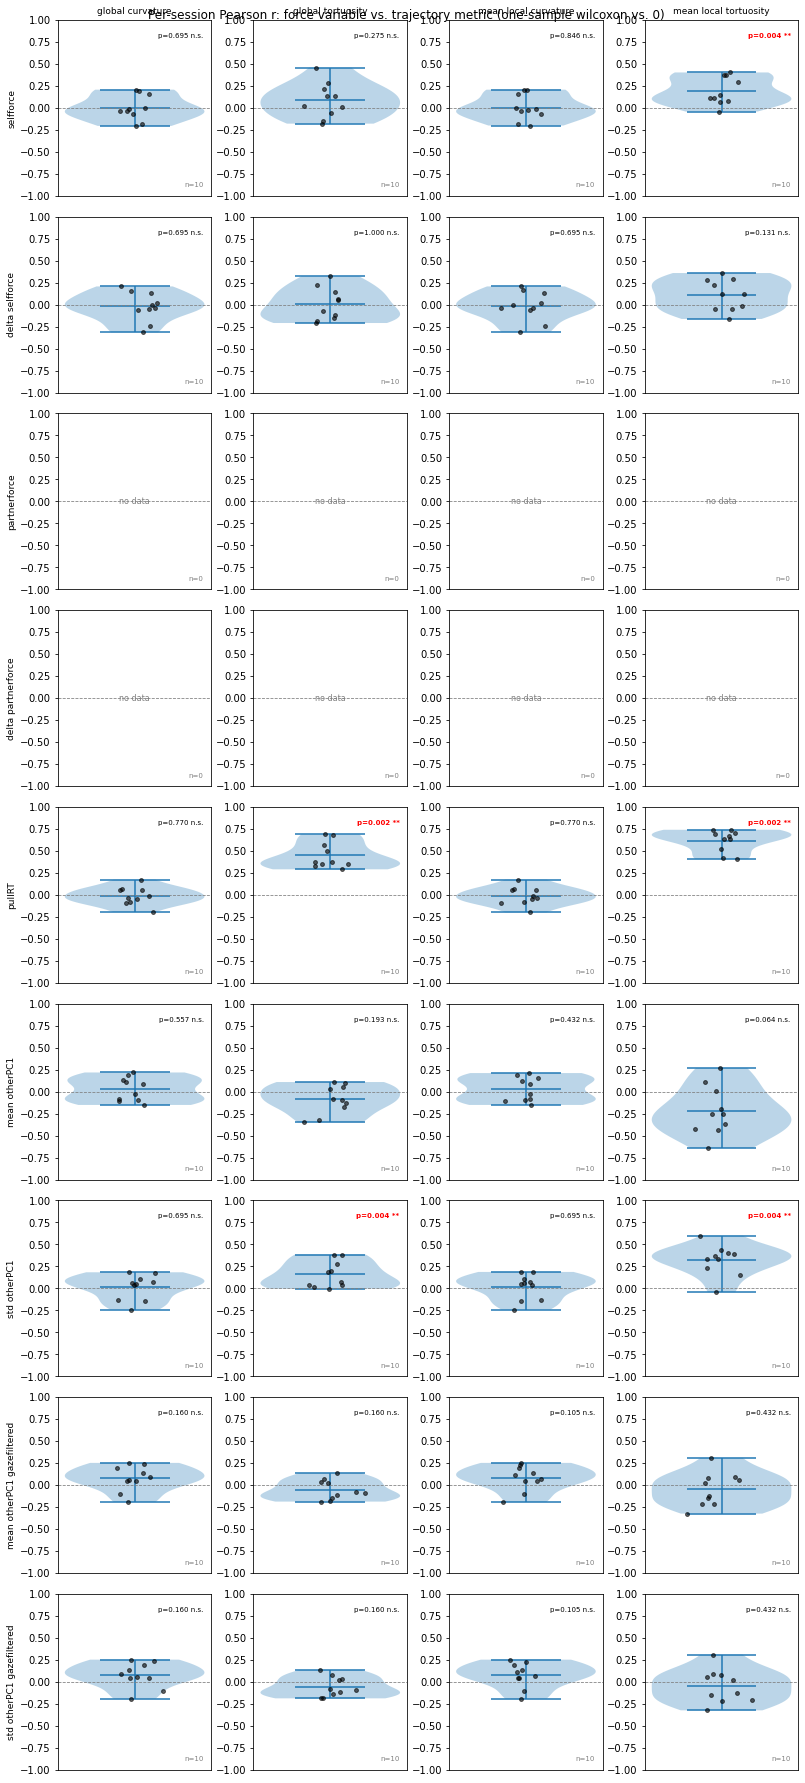

In [394]:
# calculate some matric of the pca trajectory
# before that normalize all trials into the same size, like in the neuron paper

from scipy.interpolate import interp1d
import statsmodels.formula.api as smf
from scipy.stats import ttest_1samp, wilcoxon
from scipy.stats import pearsonr

def time_normalize_trajectory(trace, n_bins=100):
    """
    trace: (L, n_components) raw PC trajectory for one pull, L varies per pull.
    Returns: (n_bins, n_components) trajectory interpolated onto a common 0-100% time axis.
    """
    L, n_components = trace.shape
    if L < 2:
        return np.full((n_bins, n_components), np.nan)

    orig_t = np.linspace(0, 1, L)
    new_t = np.linspace(0, 1, n_bins)

    out = np.zeros((n_bins, n_components))
    for c in range(n_components):
        f = interp1d(orig_t, trace[:, c], kind='linear')
        out[:, c] = f(new_t)
    return out


def compute_trajectory_metrics(traj, local_window=10):
    """
    traj: (n_bins, n_components) time-normalized trajectory in PC space.
    Returns global curvature/tortuosity (scalars) and local curvature/tortuosity
    (arrays, one value per bin, using a centered moving window).

    Curvature uses the general n-dimensional formula for a discretely-sampled curve:
        kappa(t) = sqrt(|v|^2 |a|^2 - (v.a)^2) / |v|^3
    where v, a are velocity/acceleration (1st/2nd derivatives along the trajectory).

    Tortuosity = arc length / straight-line (endpoint-to-endpoint) distance.
    """
    n_bins, n_components = traj.shape

    # velocity/acceleration via central differences
    v = np.gradient(traj, axis=0)          # (n_bins, n_components)
    a = np.gradient(v, axis=0)

    v_norm2 = np.sum(v**2, axis=1)
    a_norm2 = np.sum(a**2, axis=1)
    v_dot_a = np.sum(v * a, axis=1)

    numerator = np.sqrt(np.clip(v_norm2 * a_norm2 - v_dot_a**2, a_min=0, a_max=None))
    denom = v_norm2**1.5
    denom[denom == 0] = np.nan
    pointwise_curvature = numerator / denom  # (n_bins,)

    # global metrics
    step_lengths = np.linalg.norm(np.diff(traj, axis=0), axis=1)
    arc_length = np.sum(step_lengths)
    endpoint_dist = np.linalg.norm(traj[-1] - traj[0])
    global_tortuosity = arc_length / endpoint_dist if endpoint_dist > 0 else np.nan
    global_curvature = np.nanmean(pointwise_curvature)

    # local (moving window) metrics, centered window of size `local_window`
    half_w = local_window // 2
    local_curvature = np.full(n_bins, np.nan)
    local_tortuosity = np.full(n_bins, np.nan)

    for t in range(n_bins):
        lo = max(0, t - half_w)
        hi = min(n_bins, t + half_w + 1)
        if hi - lo < 3:
            continue

        local_curvature[t] = np.nanmean(pointwise_curvature[lo:hi])

        seg = traj[lo:hi]
        seg_arc = np.sum(np.linalg.norm(np.diff(seg, axis=0), axis=1))
        seg_endpoint = np.linalg.norm(seg[-1] - seg[0])
        local_tortuosity[t] = seg_arc / seg_endpoint if seg_endpoint > 0 else np.nan

    return {
        'pointwise_curvature': pointwise_curvature,
        'global_curvature': global_curvature,
        'global_tortuosity': global_tortuosity,
        'local_curvature': local_curvature,
        'local_tortuosity': local_tortuosity,
    }


# --- run across all pulls for one date ---
def run_metrics_for_date(pc_per_pull, n_bins=100, local_window=10):
    metrics_per_pull = {}
    for pid, trace in pc_per_pull.items():
        traj_norm = time_normalize_trajectory(trace, n_bins=n_bins)
        metrics_per_pull[pid] = {
            'traj_norm': traj_norm,
            **compute_trajectory_metrics(traj_norm, local_window=local_window)
        }
    return metrics_per_pull


# --- 1. update build_pull_metrics_df to carry delta forces + mean local metrics ---
def smooth_pc_trajectory(traj_norm, method='gaussian', window=5, sigma=1.5):
    """
    Smooth each PC dimension of a time-normalized trajectory independently, along the
    time axis. traj_norm: (n_bins, n_components).
    """
    n_bins, n_components = traj_norm.shape
    smoothed = np.zeros_like(traj_norm)
    for c in range(n_components):
        smoothed[:, c] = smooth_trace(traj_norm[:, c], method=method,
                                       window=window, sigma=sigma)
    return smoothed


def build_pull_metrics_df(df, results_per_date, n_bins=100, local_window=10,
                           smooth_pc=True, smooth_method='gaussian',
                           smooth_window=5, smooth_sigma=1.5):
    rows = []
    for date_tgt, res in results_per_date.items():
        pc_per_pull = res['pc_per_pull']
        pull_boundaries = res['pull_boundaries']

        meta_idate = (df[df['dates'] == date_tgt]
                      .drop_duplicates(subset=['pullID'])
                      .set_index('pullID'))

        for pid, start, end in pull_boundaries:
            trace = pc_per_pull[pid]
            if np.isnan(trace).all():
                continue

            traj_norm = time_normalize_trajectory(trace, n_bins=n_bins)
            if np.isnan(traj_norm).any():
                continue

            # smooth AFTER time-normalization, so the smoothing window is in consistent
            # "% of trial" units across pulls of different original durations
            if smooth_pc:
                traj_norm = smooth_pc_trajectory(traj_norm, method=smooth_method,
                                                  window=smooth_window, sigma=smooth_sigma)

            m = compute_trajectory_metrics(traj_norm, local_window=local_window)

            if pid not in meta_idate.index:
                continue
            meta_row = meta_idate.loc[pid]

            rows.append({
                'date': date_tgt,
                'pullID': pid,
                'act_animal': meta_row['act_animal'],
                'selfforce': meta_row['selfforce'],
                'partnerforce': meta_row['partnerforce'],
                'delta_selfforce': meta_row['delta_selfforce'],
                'delta_partnerforce': meta_row['delta_partnerforce'],
                'pullRT': meta_row['pullRT'],
                
                'mean_otherPC1': meta_row['mean_otherPC1'],
                'std_otherPC1': meta_row['std_otherPC1'],
                'mean_otherPC1_gazefiltered': meta_row['mean_otherPC1_gazefiltered'],
                'std_otherPC1_gazefiltered': meta_row['mean_otherPC1_gazefiltered'],
                
                'traj_norm': traj_norm,  # now the smoothed version
                'global_curvature': m['global_curvature'],
                'global_tortuosity': m['global_tortuosity'],
                'local_curvature': m['local_curvature'],
                'local_tortuosity': m['local_tortuosity'],
                'mean_local_curvature': np.nanmean(m['local_curvature']),
                'mean_local_tortuosity': np.nanmean(m['local_tortuosity']),
            })

    return pd.DataFrame(rows)


pull_metrics_df = build_pull_metrics_df(bhvevents_aligned_FR_tgt, results_per_date,
                                         n_bins=100, local_window=10,
                                         smooth_pc=True, smooth_sigma=1.5)


# --- 2. per-session correlation between each force var and each metric var ---
def compute_session_correlations(pull_metrics_df,
                                  force_vars=('selfforce', 'delta_selfforce',
                                              'partnerforce', 'delta_partnerforce'),
                                  metric_vars=('global_curvature', 'global_tortuosity',
                                               'mean_local_curvature', 'mean_local_tortuosity')):
    """
    For each session (date), Pearson r between a force variable and a metric variable,
    computed across trials within that session. Sessions with no variance in the force
    variable (e.g. delta=0 throughout, or a fixed-force session) get NaN.
    """
    rows = []
    for date_tgt, sub in pull_metrics_df.groupby('date'):
        for fvar in force_vars:
            for mvar in metric_vars:
                x = sub[fvar].values.astype(float)
                y = sub[mvar].values.astype(float)

                valid = ~np.isnan(x) & ~np.isnan(y)
                x_valid, y_valid = x[valid], y[valid]

                if len(x_valid) < 3 or np.std(x_valid) == 0 or np.std(y_valid) == 0:
                    r, p = np.nan, np.nan
                else:
                    r, p = pearsonr(x_valid, y_valid)

                rows.append({'date': date_tgt, 'force_var': fvar, 'metric_var': mvar,
                             'r': r, 'p': p, 'n_trials': len(x_valid)})
    return pd.DataFrame(rows)

predictor_vars = ('selfforce', 'delta_selfforce',
                   'partnerforce', 'delta_partnerforce', 'pullRT',
                   'mean_otherPC1', 'std_otherPC1',
                   'mean_otherPC1_gazefiltered', 'std_otherPC1_gazefiltered')

metric_vars = ('global_curvature', 'global_tortuosity',
               'mean_local_curvature', 'mean_local_tortuosity')

session_corr_df = compute_session_correlations(pull_metrics_df,
                                                force_vars=predictor_vars,
                                                metric_vars=metric_vars)



# --- 3. plot 4 (force) x 4 (metric) grid, one point per session ---
def plot_force_metric_correlations(corr_df,
                                    force_vars=('selfforce', 'delta_selfforce',
                                                'partnerforce', 'delta_partnerforce'),
                                    metric_vars=('global_curvature', 'global_tortuosity',
                                                 'mean_local_curvature', 'mean_local_tortuosity'),
                                    plot_type='violin', test='wilcoxon',
                                    figsize_per_panel=(2.8, 2.8)):
    """
    plot_type: 'violin' or 'dots'.
    test: 'ttest' (one-sample t-test vs. 0) or 'wilcoxon' (Wilcoxon signed-rank vs. 0).
          Wilcoxon is the safer default given likely small session counts / non-normality.
    Each point = one session's Pearson r between that force var and that metric var
    across trials in that session. Panel title/annotation shows the test p-value and
    significance stars.
    """
    nrows, ncols = len(force_vars), len(metric_vars)
    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(figsize_per_panel[0]*ncols, figsize_per_panel[1]*nrows),
                              squeeze=False)

    rng = np.random.default_rng(0)

    def sig_stars(p):
        if p < 0.001: return '***'
        if p < 0.01: return '**'
        if p < 0.05: return '*'
        return 'n.s.'

    for i, fvar in enumerate(force_vars):
        for j, mvar in enumerate(metric_vars):
            ax = axes[i, j]
            sub = corr_df[(corr_df['force_var'] == fvar) & (corr_df['metric_var'] == mvar)]
            r_vals = sub['r'].dropna().values

            if len(r_vals) < 2:
                ax.text(0.5, 0.5, 'no data' if len(r_vals) == 0 else 'n=1',
                        ha='center', va='center', transform=ax.transAxes,
                        fontsize=8, color='gray')
                p_val = np.nan
            else:
                x_jit = rng.normal(1, 0.04, size=len(r_vals))
                if plot_type == 'violin':
                    parts = ax.violinplot(r_vals, showmeans=True, showextrema=True)
                    ax.scatter(x_jit, r_vals, color='black', alpha=0.6, s=15, zorder=3)
                else:
                    ax.scatter(x_jit, r_vals, color='black', alpha=0.7, s=20)

                # one-sample test vs. 0
                if test == 'ttest':
                    stat, p_val = ttest_1samp(r_vals, 0)
                elif test == 'wilcoxon':
                    # wilcoxon requires not-all-zero differences
                    if np.all(r_vals == 0):
                        p_val = 1.0
                    else:
                        stat, p_val = wilcoxon(r_vals)
                else:
                    raise ValueError(f"unknown test: {test}")

                stars = sig_stars(p_val)
                color = 'red' if p_val < 0.05 else 'black'
                ax.text(0.95, 0.90, f'p={p_val:.3f} {stars}', transform=ax.transAxes,
                        ha='right', fontsize=7, color=color, fontweight='bold' if p_val < 0.05 else 'normal')

            ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
            ax.set_ylim(-1, 1)
            ax.set_xticks([])

            if i == 0:
                ax.set_title(mvar.replace('_', ' '), fontsize=9)
            if j == 0:
                ax.set_ylabel(fvar.replace('_', ' '), fontsize=9)

            ax.text(0.95, 0.05, f'n={len(r_vals)}', transform=ax.transAxes,
                    ha='right', fontsize=7, color='gray')

    fig.suptitle(f'Per-session Pearson r: force variable vs. trajectory metric '
                 f'(one-sample {test} vs. 0)')
    fig.tight_layout()
    return fig, axes


fig, axes = plot_force_metric_correlations(session_corr_df,
                                            force_vars=predictor_vars,
                                            metric_vars=metric_vars,
                                            plot_type='violin', test='wilcoxon',
                                            figsize_per_panel=(2.8, 2.8))

savefig = 1
if savefig:
    figsavefolder = data_saved_folder+"fig_for_basic_neural_analysis_allsessions_basicEvents_PCA_makeBhvNeuronVideos_PullStartToPull_section_continuousBhv_PCAonBhv/"+cameraID+"/"+\
    animal1_filenames[0]+"_"+animal2_filenames[0]+"_"+recordedanimals[0]+"Recorded/"

    if not os.path.exists(figsavefolder):
        os.makedirs(figsavefolder)

    fig.savefig(figsavefolder+'prepull_aligned_PCspace_trajectory_metrics_and_force_'+condition_tgt+'.pdf')
    
    
    
    
    

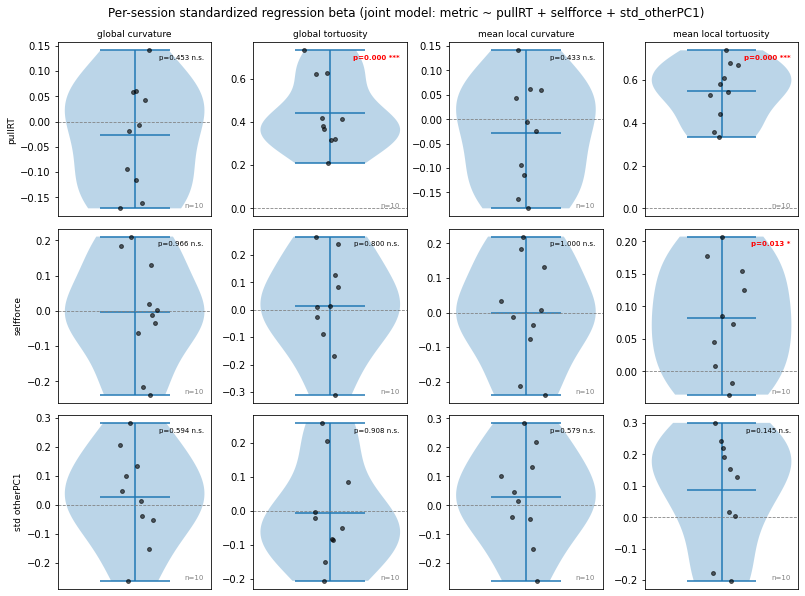

In [395]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp, wilcoxon

def compute_session_regressions(pull_metrics_df, predictor_vars, metric_vars,
                                 min_trials=None, standardize=True):
    """
    For each session (date), fit metric ~ predictor_1 + predictor_2 + ... (multiple OLS),
    across trials within that session. Predictors and outcome are z-scored within-session
    first if standardize=True, so coefficients are standardized betas (comparable in scale
    across sessions/predictors, and roughly comparable to the earlier per-session Pearson r's,
    but now with each predictor partialling out the others).

    Predictors with zero variance in a given session (e.g. partnerforce in a variable-self
    session) are dropped from that session's model rather than crashing the fit; their
    beta/p for that session come back as NaN.
    """
    if min_trials is None:
        min_trials = len(predictor_vars) + 5  # rough rule of thumb: need more trials than predictors

    rows = []
    for date_tgt, sub in pull_metrics_df.groupby('date'):
        sub = sub.dropna(subset=list(predictor_vars) + list(metric_vars))
        if len(sub) < min_trials:
            for mvar in metric_vars:
                for p in predictor_vars:
                    rows.append({'date': date_tgt, 'predictor': p, 'metric_var': mvar,
                                 'beta': np.nan, 'p_value': np.nan, 'n_trials': len(sub),
                                 'skipped_reason': 'too_few_trials'})
            continue

        # which predictors actually vary in this session
        valid_preds = [p for p in predictor_vars if sub[p].std() > 0]
        dropped_preds = [p for p in predictor_vars if p not in valid_preds]

        if standardize:
            sub_z = sub.copy()
            for col in list(valid_preds) + list(metric_vars):
                s = sub_z[col].std()
                sub_z[col] = 0.0 if s == 0 else (sub_z[col] - sub_z[col].mean()) / s
        else:
            sub_z = sub

        for mvar in metric_vars:
            if len(valid_preds) == 0:
                for p in predictor_vars:
                    rows.append({'date': date_tgt, 'predictor': p, 'metric_var': mvar,
                                 'beta': np.nan, 'p_value': np.nan, 'n_trials': len(sub),
                                 'skipped_reason': 'no_variance_in_any_predictor'})
                continue

            formula = f"{mvar} ~ " + " + ".join(valid_preds)
            try:
                model = smf.ols(formula, data=sub_z).fit()
            except Exception as e:
                for p in predictor_vars:
                    rows.append({'date': date_tgt, 'predictor': p, 'metric_var': mvar,
                                 'beta': np.nan, 'p_value': np.nan, 'n_trials': len(sub),
                                 'skipped_reason': f'fit_error:{e}'})
                continue

            for p in predictor_vars:
                if p in valid_preds:
                    rows.append({'date': date_tgt, 'predictor': p, 'metric_var': mvar,
                                 'beta': model.params.get(p, np.nan),
                                 'p_value': model.pvalues.get(p, np.nan),
                                 'n_trials': len(sub), 'skipped_reason': None})
                else:
                    rows.append({'date': date_tgt, 'predictor': p, 'metric_var': mvar,
                                 'beta': np.nan, 'p_value': np.nan, 'n_trials': len(sub),
                                 'skipped_reason': 'zero_variance_this_session'})

    return pd.DataFrame(rows)


def plot_predictor_metric_betas(reg_df, predictor_vars, metric_vars,
                                 plot_type='violin', test='wilcoxon',
                                 figsize_per_panel=(2.8, 2.8)):
    """
    Same layout/logic as the correlation grid, but each point is a session's standardized
    regression coefficient (beta) for that predictor, from the joint model for that metric.
    """
    nrows, ncols = len(predictor_vars), len(metric_vars)
    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(figsize_per_panel[0]*ncols, figsize_per_panel[1]*nrows),
                              squeeze=False)
    rng = np.random.default_rng(0)

    def sig_stars(p):
        if p < 0.001: return '***'
        if p < 0.01: return '**'
        if p < 0.05: return '*'
        return 'n.s.'

    for i, pvar in enumerate(predictor_vars):
        for j, mvar in enumerate(metric_vars):
            ax = axes[i, j]
            sub = reg_df[(reg_df['predictor'] == pvar) & (reg_df['metric_var'] == mvar)]
            beta_vals = sub['beta'].dropna().values

            if len(beta_vals) < 2:
                ax.text(0.5, 0.5, 'no data' if len(beta_vals) == 0 else 'n=1',
                        ha='center', va='center', transform=ax.transAxes,
                        fontsize=8, color='gray')
                p_val = np.nan
            else:
                x_jit = rng.normal(1, 0.04, size=len(beta_vals))
                if plot_type == 'violin':
                    ax.violinplot(beta_vals, showmeans=True, showextrema=True)
                    ax.scatter(x_jit, beta_vals, color='black', alpha=0.6, s=15, zorder=3)
                else:
                    ax.scatter(x_jit, beta_vals, color='black', alpha=0.7, s=20)

                if test == 'ttest':
                    _, p_val = ttest_1samp(beta_vals, 0)
                elif test == 'wilcoxon':
                    p_val = 1.0 if np.all(beta_vals == 0) else wilcoxon(beta_vals)[1]
                else:
                    raise ValueError(f"unknown test: {test}")

                stars = sig_stars(p_val)
                color = 'red' if p_val < 0.05 else 'black'
                ax.text(0.95, 0.90, f'p={p_val:.3f} {stars}', transform=ax.transAxes,
                        ha='right', fontsize=7, color=color,
                        fontweight='bold' if p_val < 0.05 else 'normal')

            ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
            ax.set_xticks([])
            if i == 0:
                ax.set_title(mvar.replace('_', ' '), fontsize=9)
            if j == 0:
                ax.set_ylabel(pvar.replace('_', ' '), fontsize=9)
            ax.text(0.95, 0.05, f'n={len(beta_vals)}', transform=ax.transAxes,
                    ha='right', fontsize=7, color='gray')

    fig.suptitle(f'Per-session standardized regression beta '
                 f'(joint model: metric ~ {" + ".join(predictor_vars)})')
    fig.tight_layout()
    return fig, axes


# --- your primary target: pullRT, selfforce, mean_otherPC1, jointly ---
predictor_vars_joint = ('pullRT', 'selfforce', 'std_otherPC1')
metric_vars = ('global_curvature', 'global_tortuosity',
               'mean_local_curvature', 'mean_local_tortuosity')

session_reg_df = compute_session_regressions(pull_metrics_df,
                                              predictor_vars=predictor_vars_joint,
                                              metric_vars=metric_vars)

fig, axes = plot_predictor_metric_betas(session_reg_df,
                                         predictor_vars=predictor_vars_joint,
                                         metric_vars=metric_vars,
                                         plot_type='violin', test='ttest')

savefig = 1
if savefig:
    figsavefolder = data_saved_folder+"fig_for_basic_neural_analysis_allsessions_basicEvents_PCA_makeBhvNeuronVideos_PullStartToPull_section_continuousBhv_PCAonBhv/"+cameraID+"/"+\
    animal1_filenames[0]+"_"+animal2_filenames[0]+"_"+recordedanimals[0]+"Recorded/"
    if not os.path.exists(figsavefolder):
        os.makedirs(figsavefolder)
    fig.savefig(figsavefolder+'prepull_aligned_PCspace_trajectory_metrics_JOINTmodel_pullRT_selfforce_otherPC1_'+condition_tgt+'.pdf')

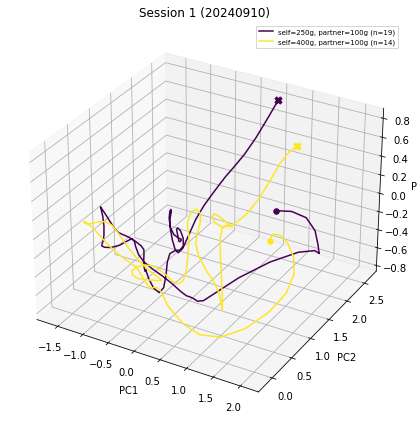

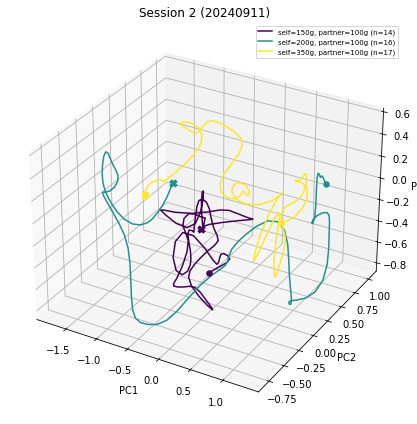

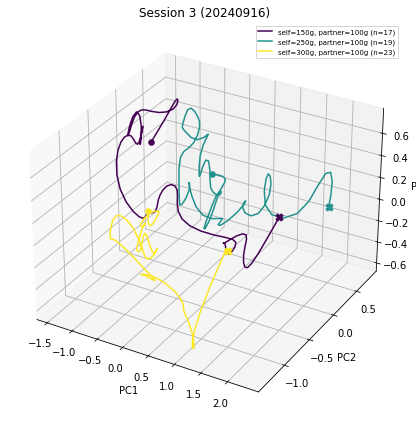

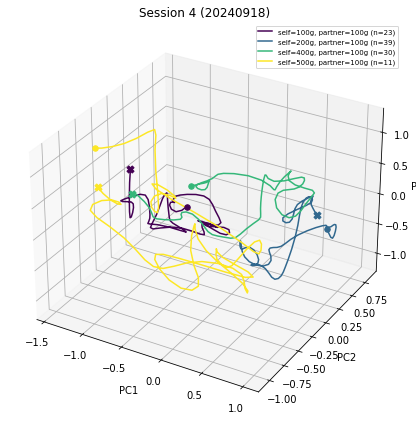

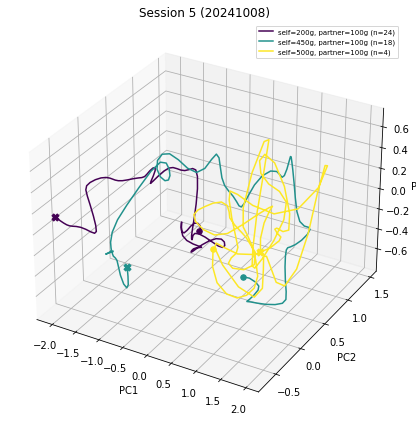

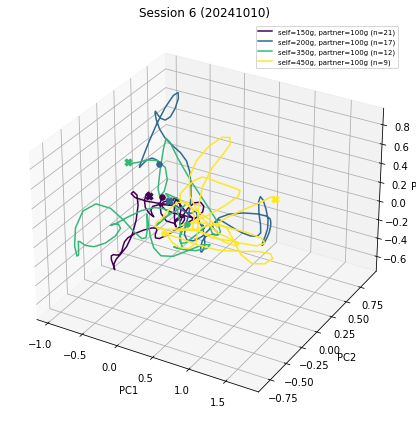

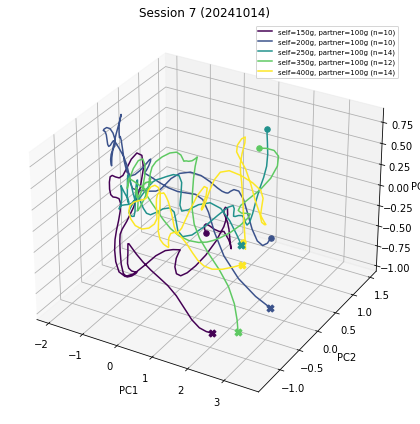

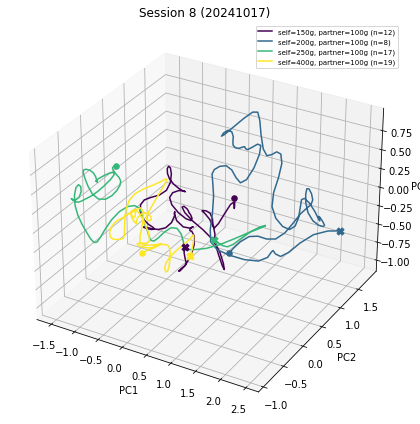

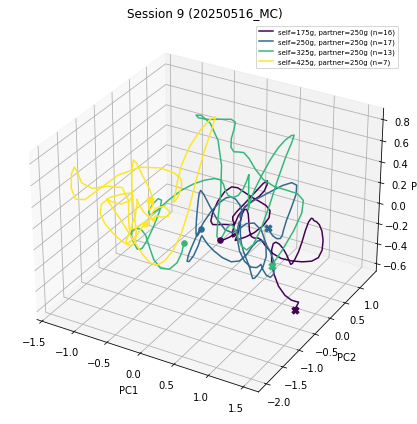

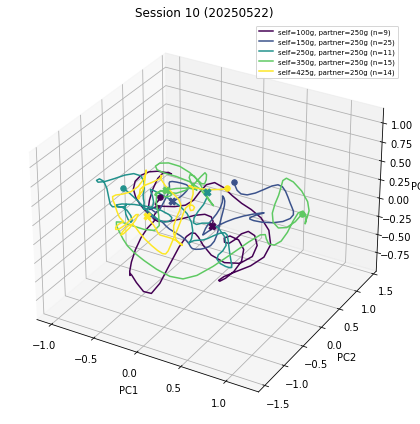

In [396]:
# plot the trajectory for each session, separating based on the raw force level

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D projection)
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def plot_3d_pc_trajectories_per_session(pull_metrics_df, min_n=3, figsize=(7, 6)):
    """
    For each session (date), plot a 3D trajectory (PC1, PC2, PC3) for each
    (selfforce, partnerforce) condition, averaged across pulls within that session.
    Figure number = session index (in date order).
    """
    dates_list = sorted(pull_metrics_df['date'].unique())
    figs = {}

    for isession, date_tgt in enumerate(dates_list, start=1):
        df_date = pull_metrics_df[pull_metrics_df['date'] == date_tgt]

        conditions = (df_date.groupby(['selfforce', 'partnerforce'])
                      .size().reset_index(name='n'))
        conditions = conditions[conditions['n'] >= min_n].sort_values(['selfforce', 'partnerforce'])

        if len(conditions) == 0:
            print(f"session {isession} ({date_tgt}): no conditions with n >= {min_n}, skipping")
            continue

        fig = plt.figure(isession, figsize=figsize)
        ax = fig.add_subplot(111, projection='3d')
        colors = cm.viridis(np.linspace(0, 1, len(conditions)))

        for (_, row), color in zip(conditions.iterrows(), colors):
            sf, pf, n = row['selfforce'], row['partnerforce'], row['n']
            sub = df_date[(df_date['selfforce'] == sf) & (df_date['partnerforce'] == pf)]

            # stack (n_pulls, n_bins, 3), average across pulls -> (n_bins, 3)
            stacked = np.stack(sub['traj_norm'].values, axis=0)
            mean_traj = np.nanmean(stacked, axis=0)  # (n_bins, 3)

            ax.plot(mean_traj[:, 0], mean_traj[:, 1], mean_traj[:, 2],
                     color=color, label=f'self={sf}g, partner={pf}g (n={n})')
            # mark trial start and pull time
            ax.scatter(*mean_traj[0], color=color, marker='o', s=30)   # start
            ax.scatter(*mean_traj[-1], color=color, marker='X', s=50)  # pull

        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.set_zlabel('PC3')
        ax.set_title(f'Session {isession} ({date_tgt})')
        ax.legend(fontsize=7, loc='best')
        fig.tight_layout()

        figs[isession] = fig

    return figs


session_figs = plot_3d_pc_trajectories_per_session(pull_metrics_df, min_n=3)

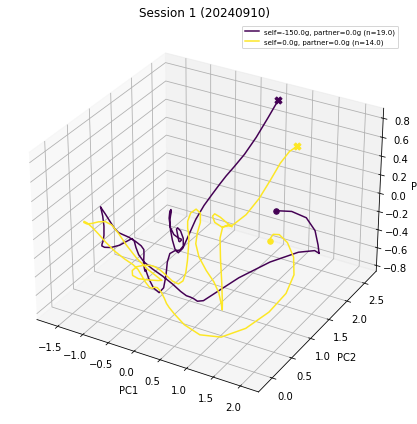

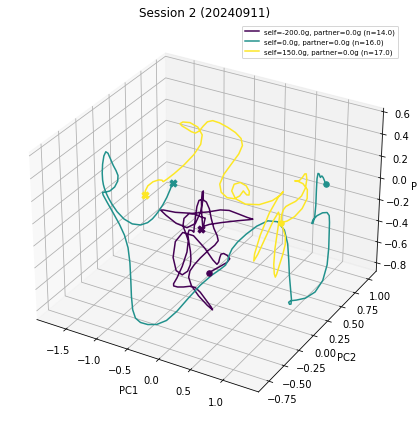

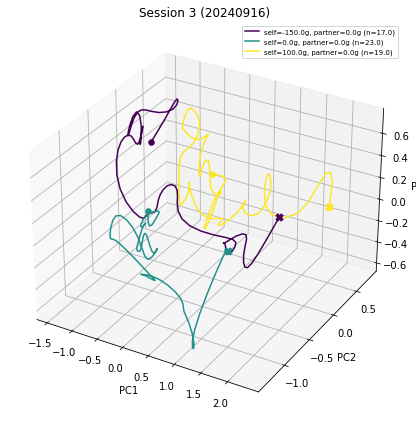

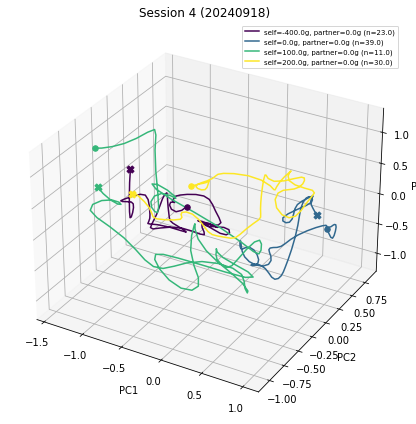

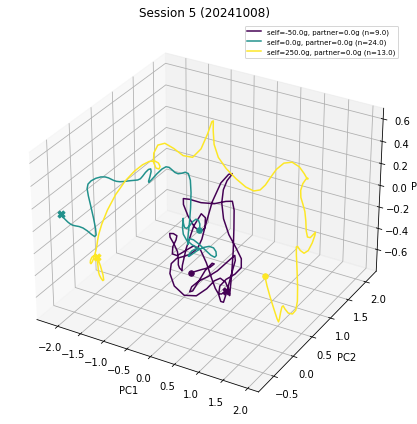

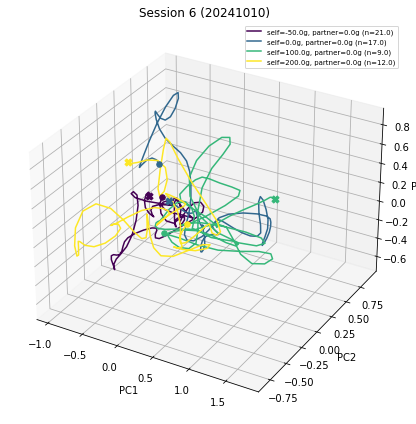

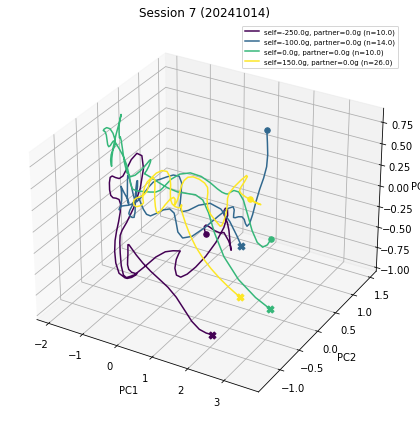

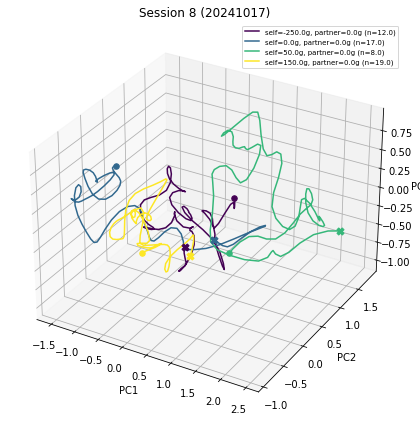

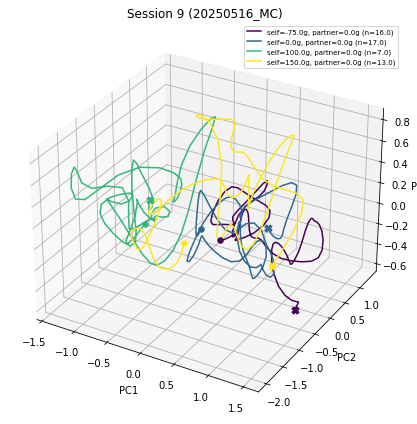

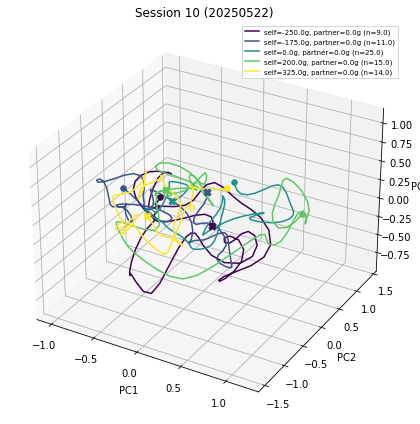

In [397]:
# plot the trajectory for each session, separating based on the delta force level

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D projection)
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def plot_3d_pc_trajectories_per_session(pull_metrics_df, min_n=3, figsize=(7, 6)):
    """
    For each session (date), plot a 3D trajectory (PC1, PC2, PC3) for each
    (selfforce, partnerforce) condition, averaged across pulls within that session.
    Figure number = session index (in date order).
    """
    dates_list = sorted(pull_metrics_df['date'].unique())
    figs = {}

    for isession, date_tgt in enumerate(dates_list, start=1):
        df_date = pull_metrics_df[pull_metrics_df['date'] == date_tgt]

        conditions = (df_date.groupby(['delta_selfforce', 'delta_partnerforce'])
                      .size().reset_index(name='n'))
        conditions = conditions[conditions['n'] >= min_n].sort_values(['delta_selfforce', 'delta_partnerforce'])

        if len(conditions) == 0:
            print(f"session {isession} ({date_tgt}): no conditions with n >= {min_n}, skipping")
            continue

        fig = plt.figure(isession, figsize=figsize)
        ax = fig.add_subplot(111, projection='3d')
        colors = cm.viridis(np.linspace(0, 1, len(conditions)))

        for (_, row), color in zip(conditions.iterrows(), colors):
            sf, pf, n = row['delta_selfforce'], row['delta_partnerforce'], row['n']
            sub = df_date[(df_date['delta_selfforce'] == sf) & (df_date['delta_partnerforce'] == pf)]

            # stack (n_pulls, n_bins, 3), average across pulls -> (n_bins, 3)
            stacked = np.stack(sub['traj_norm'].values, axis=0)
            mean_traj = np.nanmean(stacked, axis=0)  # (n_bins, 3)

            ax.plot(mean_traj[:, 0], mean_traj[:, 1], mean_traj[:, 2],
                     color=color, label=f'self={sf}g, partner={pf}g (n={n})')
            # mark trial start and pull time
            ax.scatter(*mean_traj[0], color=color, marker='o', s=30)   # start
            ax.scatter(*mean_traj[-1], color=color, marker='X', s=50)  # pull

        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.set_zlabel('PC3')
        ax.set_title(f'Session {isession} ({date_tgt})')
        ax.legend(fontsize=7, loc='best')
        fig.tight_layout()

        figs[isession] = fig

    return figs


session_figs = plot_3d_pc_trajectories_per_session(pull_metrics_df, min_n=3)

In [398]:
pull_metrics_df

,date,pullID,act_animal,selfforce,partnerforce,delta_selfforce,delta_partnerforce,pullRT,mean_otherPC1,std_otherPC1,mean_otherPC1_gazefiltered,std_otherPC1_gazefiltered,traj_norm,global_curvature,global_tortuosity,local_curvature,local_tortuosity,mean_local_curvature,mean_local_tortuosity
0,20240910,0,kanga,400,100,0.0,0.0,22.733333,-1.185135,0.655186,-1.311719,-1.311719,"[[2.272102386978306, -1.4936583185182866, -0.7...",2.999147e+00,18.025522,"[1.7613295633722632, 4.402447288166198, 4.0410...","[3.6374404883399, 5.283201628101914, 4.8764366...",3.033096e+00,3.644245
1,20240910,1,kanga,400,100,0.0,0.0,4.533333,-0.406337,0.977928,-0.528009,-0.528009,"[[3.2736372826249336, 1.9562394959190583, 0.70...",3.292161e+00,10.881003,"[0.6342824121054654, 1.0133374391052954, 1.051...","[1.217772325145595, 1.2359026853903796, 1.3004...",3.296517e+00,2.123970
2,20240910,2,kanga,400,100,0.0,0.0,5.100000,0.209910,1.143356,0.292058,0.292058,"[[0.23308733495396866, -0.32998689774555195, -...",3.152012e+14,7.401162,"[0.5362678392519072, 0.8317632676020575, 1.010...","[1.052898036305674, 1.0920077871935647, 1.1983...",5.117555e+14,1.691317
3,20240910,3,kanga,400,100,0.0,0.0,7.966667,-0.982104,1.145240,-0.325622,-0.325622,"[[-5.625117860716156, 0.915141676054355, -0.57...",3.028540e+00,5.730705,"[0.06702114343960819, 0.07105353252104246, 0.0...","[1.018294672686942, 1.0209932243296562, 1.0223...",3.042038e+00,1.914183
4,20240910,4,kanga,400,100,0.0,0.0,11.900000,-0.719546,1.288191,-0.380218,-0.380218,"[[3.3001685798781946, 5.472866507487483, 1.961...",4.595802e+00,8.972080,"[0.169953293630982, 0.1940397249194034, 0.2086...","[1.051819661864275, 1.1117465117006176, 1.1886...",4.602597e+00,2.370429
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,20250522,69,kanga,250,250,-175.0,0.0,7.200000,-1.191473,0.736094,-0.410875,-0.410875,"[[-0.6457794884809809, 4.9438146864096995, 1.1...",1.703017e+00,9.112226,"[0.2631953249491598, 0.2809200676282967, 0.331...","[1.0433200992868599, 1.0561500016828098, 1.055...",1.721426e+00,2.076797
590,20250522,70,kanga,250,250,-175.0,0.0,1.333333,0.966050,0.233436,0.966050,0.966050,"[[-0.5066896567150221, -0.8219319912242329, -0...",4.086442e+00,2.390787,"[0.5177865410785011, 0.7718585521305561, 1.150...","[1.0027705092897663, 1.0072914527315346, 1.018...",4.096390e+00,1.373090
591,20250522,71,kanga,250,250,-175.0,0.0,5.166667,-1.277173,1.641141,0.483969,0.483969,"[[-1.388819210287307, -1.8131488639953988, -0....",1.866711e+00,21.527164,"[0.4759635541832019, 0.5882156117457361, 0.697...","[1.0735971231054346, 1.0812033493347588, 1.122...",1.881557e+00,2.191239
592,20250522,72,kanga,250,250,-175.0,0.0,6.233333,-0.529913,1.960915,0.337976,0.337976,"[[-1.5786969169546186, -2.175951045820414, 1.3...",2.215764e+00,17.935626,"[0.5900126531951795, 1.0922762718092733, 1.332...","[1.0366499566837728, 1.0995020619280147, 1.226...",2.223180e+00,2.276593
